In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/divyanshyecho/imerge-2000-2024-daily/imerg_india_025_jjas_2000_2024.nc
/kaggle/input/datasets/divyanshyecho/bsiso-1981-2026/BSISO.INDEX.NORM.LY.data
/kaggle/input/datasets/divyanshyecho/vorticity-center-2000-2022/lps_daily_2000_2022.parquet


In [2]:
import os
ROOT = "/kaggle/input"
for dp, dn, fn in os.walk(ROOT):
    d = dp.replace(ROOT, "").count(os.sep)
    print("  " * d + os.path.basename(dp) + "/")
    for f in sorted(fn):
        mb = os.path.getsize(os.path.join(dp, f)) / 1e6
        print("  " * (d + 1) + f"{f}   ({mb:,.2f} MB)")

input/
  datasets/
    divyanshyecho/
      imerge-2000-2024-daily/
        imerg_india_025_jjas_2000_2024.nc   (225.03 MB)
      bsiso-1981-2026/
        BSISO.INDEX.NORM.LY.data   (1.08 MB)
      vorticity-center-2000-2022/
        lps_daily_2000_2022.parquet   (0.11 MB)


In [3]:
import os, numpy as np, pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)

ALL = [os.path.join(dp, f) for dp, _, fs in os.walk("/kaggle/input") for f in fs]

def find(*keys):
    return sorted([p for p in ALL if all(k.lower() in p.lower() for k in keys)], key=len)

BSISO_PATH = (find("bsiso") or [None])[0]
LPS_PATH   = (find("vortic") or find("lps") or [None])[0]
IMERG_PATH = (find("imerg") or [None])[0]

print("BSISO :", BSISO_PATH)
print("LPS   :", LPS_PATH)
print("IMERG :", IMERG_PATH)

def peek(path, n=5):
    if not path: return
    ext = os.path.splitext(path)[1].lower()
    print("\n" + "=" * 78); print(path); print("=" * 78)
    try:
        if ext in (".csv", ".txt", ".dat", ".data", ".tsv"):
            with open(path, errors="replace") as f:
                for _ in range(8):
                    print(repr(f.readline()[:180]))
        elif ext == ".parquet":
            d = pd.read_parquet(path)
            print("shape=", d.shape); print(d.dtypes.to_string()); print(d.head(n).to_string())
        elif ext in (".nc", ".nc4"):
            import xarray as xr
            with xr.open_dataset(path) as ds: print(ds)
    except Exception as e:
        print(f"!! {type(e).__name__}: {e}")

for p in (BSISO_PATH, LPS_PATH, IMERG_PATH): peek(p)

BSISO : /kaggle/input/datasets/divyanshyecho/bsiso-1981-2026/BSISO.INDEX.NORM.LY.data
LPS   : /kaggle/input/datasets/divyanshyecho/vorticity-center-2000-2022/lps_daily_2000_2022.parquet
IMERG : /kaggle/input/datasets/divyanshyecho/imerge-2000-2024-daily/imerg_india_025_jjas_2000_2024.nc

/kaggle/input/datasets/divyanshyecho/bsiso-1981-2026/BSISO.INDEX.NORM.LY.data
' YEAR  DAY  BSISO1-1 BSISO1-2 BSISO2-1 BSISO2-2 BSISO1  BSISO2\n'
'  1981   1    0.240   -0.034    0.467   -0.108    0.243    0.480\n'
'  1981   2    0.454    0.426    0.846   -0.128    0.623    0.856\n'
'  1981   3    0.266    0.740    0.664    0.279    0.786    0.721\n'
'  1981   4   -0.175    0.363    0.358    0.175    0.402    0.399\n'
'  1981   5   -0.203    0.471    0.144    0.050    0.512    0.152\n'
'  1981   6   -0.208    0.790    0.312    0.513    0.817    0.600\n'
'  1981   7   -0.261    0.676    0.157    0.697    0.725    0.715\n'

/kaggle/input/datasets/divyanshyecho/vorticity-center-2000-2022/lps_daily_2000_202

In [4]:
def load_bsiso(path):
    df = pd.read_csv(path, sep=r"\s+", skiprows=1, header=None,
                     names=["year","doy","pc1","pc2","b2pc1","b2pc2","amp1","amp2"])
    df["date"] = (pd.to_datetime(df["year"].astype(str), format="%Y")
                  + pd.to_timedelta(df["doy"] - 1, unit="D"))
    df = df.sort_values("date").reset_index(drop=True)
    cols = ["pc1","pc2","b2pc1","b2pc2","amp1","amp2"]

    bad = df[["pc1","pc2","amp1"]].le(-999.0).any(axis=1)
    print("missing days:", bad.sum(), df.loc[bad,"date"].dt.strftime("%Y-%m-%d").tolist())

    # only isolated single-day gaps may be interpolated
    runs = (bad != bad.shift()).cumsum()[bad]
    longest = runs.value_counts().max() if bad.any() else 0
    assert longest <= 1, f"gap of {longest} consecutive days -- too long to interpolate"

    # CHECK FIRST, on real rows only, before inventing anything
    real = df.loc[~bad]
    err = (np.hypot(real["pc1"], real["pc2"]) - real["amp1"]).abs().max()
    print(f"max |hypot(PC1,PC2) - stored amp| on ORIGINAL rows = {err:.3e}")
    assert err < 5e-3, "amplitude does not reconstruct -- wrong columns"

    # now fill the isolated gap
    df.loc[bad, cols] = np.nan
    df[cols] = df[cols].interpolate(limit=1)
    df["interpolated"] = bad
    print("remaining NaN after fill:", int(df["pc1"].isna().sum()))

    th = np.mod(np.arctan2(df["pc1"], -df["pc2"]), 2*np.pi)
    df["theta"] = th
    df["phase"] = np.floor(th / (np.pi/4)) + 1
    df.loc[df["pc1"].isna(), "phase"] = np.nan
    df["amp"] = np.hypot(df["pc1"], df["pc2"])    # always from the PCs, never the file column
    return df[["date","pc1","pc2","amp","theta","phase","interpolated"]]

bsiso = load_bsiso(BSISO_PATH)
print(bsiso.shape, bsiso["date"].min().date(), "->", bsiso["date"].max().date())

missing days: 1 ['2015-06-21']
max |hypot(PC1,PC2) - stored amp| on ORIGINAL rows = 1.165e-03
remaining NaN after fill: 0
(16621, 7) 1981-01-01 -> 2026-07-04


In [5]:
REF = {1:288, 2:401, 3:388, 4:322, 5:473, 6:299, 7:333, 8:302}   # JJAS 2000-2022
m = bsiso["date"].dt.month.between(6,9) & bsiso["date"].dt.year.between(2000,2022)
got = bsiso.loc[m,"phase"].value_counts().sort_index().astype(int).to_dict()

print(f"{'phase':>6}{'derived':>9}{'reference':>11}{'diff':>7}")
agree = True
for p in range(1,9):
    g, r = got.get(p,0), REF[p]
    print(f"{p:>6}{g:>9}{r:>11}{g-r:>7}")
    agree &= (g == r)
print(f"\ntotal = {sum(got.values())}  (23 yrs x 122 JJAS days = 2806)")
print("CONVENTION CONFIRMED" if agree else "*** MISMATCH - STOP, do not continue ***")

 phase  derived  reference   diff
     1      288        288      0
     2      401        401      0
     3      388        388      0
     4      322        322      0
     5      473        473      0
     6      299        299      0
     7      333        333      0
     8      302        302      0

total = 2806  (23 yrs x 122 JJAS days = 2806)
CONVENTION CONFIRMED


In [6]:
LPS_COLS = {"track":"track_id", "date":"date", "lat":"lat", "lon":"lon",
            "strength":"min_streamfn"}      # <-- adjust after STEP 2 output
STRENGTH_SIGN = -1.0                        # min_streamfn is negative; flip so bigger = stronger

lps = (pd.read_parquet(LPS_PATH) if LPS_PATH.endswith(".parquet")
       else pd.read_csv(LPS_PATH))
lps = lps.rename(columns={v:k for k,v in LPS_COLS.items()})
lps["date"] = pd.to_datetime(lps["date"])
lps["strength"] = STRENGTH_SIGN * lps["strength"]
lps = lps.merge(bsiso, on="date", how="left")

gen = (lps.sort_values("date").groupby("track", as_index=False).first())

print(f"system-days   : {len(lps):,}")
print(f"tracks        : {lps['track'].nunique():,}")
print(f"range         : {lps['date'].min().date()} -> {lps['date'].max().date()}")
print(f"months        : {sorted(lps['date'].dt.month.unique())}")
print(f"no BSISO match: {lps['phase'].isna().sum()}")

Y0, Y1 = int(lps["date"].dt.year.min()), int(lps["date"].dt.year.max())
season_days = bsiso[bsiso["date"].dt.month.between(6,9)
                    & bsiso["date"].dt.year.between(Y0,Y1)]
phase_days = season_days["phase"].value_counts().sort_index()
print(f"\nJJAS {Y0}-{Y1}: {len(season_days):,} days")

system-days   : 2,232
tracks        : 345
range         : 2000-06-02 -> 2022-09-30
months        : [np.int32(6), np.int32(7), np.int32(8), np.int32(9)]
no BSISO match: 0

JJAS 2000-2022: 2,806 days


In [7]:
RNG = np.random.default_rng(20260923)
N_PERM = 300        # raise to 1000 once it runs clean

def redate_tracks(df, rng, years):
    """Move each storm rigidly to a random other year, keeping month/day exactly."""
    out = df.copy()
    orig = out.groupby("track")["date"].transform("min").dt.year
    pick = pd.Series(rng.choice(years, size=out["track"].nunique()),
                     index=np.sort(out["track"].unique()))
    shift = (out["track"].map(pick) - orig).astype(int)
    out["date"] = pd.to_datetime(dict(year=out["date"].dt.year + shift,
                                      month=out["date"].dt.month,
                                      day=out["date"].dt.day))
    return out

def attach_phase(df, b):
    return (df.drop(columns=["phase","amp","pc1","pc2","theta"], errors="ignore")
              .merge(b[["date","phase","amp"]], on="date", how="left"))

years = np.arange(Y0, Y1 + 1)

In [8]:
def genesis_rate(g, pdays):
    c = g.dropna(subset=["phase"])["phase"].value_counts().reindex(range(1,9), fill_value=0).sort_index()
    return c, c / pdays.reindex(range(1,9))

cnt_obs, rate_obs = genesis_rate(gen, phase_days)
overall = len(gen.dropna(subset=["phase"])) / phase_days.sum()
spread  = lambda r: float((((r - overall)**2) / overall).sum())
obs_stat = spread(rate_obs)

null_stats, null_rates = [], []
for _ in range(N_PERM):
    s = attach_phase(redate_tracks(gen[["track","date"]], RNG, years), bsiso)
    _, r = genesis_rate(s, phase_days)
    null_rates.append(r.values); null_stats.append(spread(r))
null_stats, null_rates = np.array(null_stats), np.array(null_rates)
p_gen = float((null_stats >= obs_stat).mean())

tab = pd.DataFrame({
    "phase_days": phase_days.reindex(range(1,9)).values,
    "genesis": cnt_obs.values,
    "rate_per_day": rate_obs.values,
    "vs_overall_%": 100*(rate_obs.values/overall - 1),
    "null_p05": np.nanpercentile(null_rates,5,axis=0),
    "null_p95": np.nanpercentile(null_rates,95,axis=0),
}, index=pd.Index(range(1,9), name="phase"))

print(tab.round(4).to_string())
print(f"\noverall {overall:.4f}/day | range {rate_obs.max()/rate_obs.min():.2f}x | PERM p = {p_gen:.4f}")
tab.to_csv("/kaggle/working/K1_genesis_by_phase.csv")

       phase_days  genesis  rate_per_day  vs_overall_%  null_p05  null_p95
phase                                                                     
1             288       19        0.0660      -46.3426    0.0972    0.1597
2             401       39        0.0973      -20.8978    0.0973    0.1546
3             388       49        0.1263        2.7148    0.0954    0.1469
4             322       48        0.1491       21.2422    0.0930    0.1430
5             473       74        0.1564       27.2445    0.0994    0.1459
6             299       43        0.1438       16.9677    0.1035    0.1640
7             333       36        0.1081      -12.0721    0.0961    0.1502
8             302       37        0.1225       -0.3532    0.0894    0.1457

overall 0.1230/day | range 2.37x | PERM p = 0.0167


LPS genesis is 2.4× more frequent when the BSISO is in phase 5 than in phase 1 (p = 0.017, track re-dating null), which is the right way round physically: it peaks when the wave is over India.

In [9]:
sysd   = lps.dropna(subset=["phase","strength"])
int_all = sysd["strength"].mean()
int_obs = sysd.groupby("phase")["strength"].mean().reindex(range(1,9))
ispread = lambda s: float(np.nansum((s - int_all)**2)) / int_all**2
obs_i   = ispread(int_obs.values)

null_i, null_prof = [], []
for _ in range(N_PERM):
    s = attach_phase(redate_tracks(sysd[["track","date","strength"]], RNG, years), bsiso)
    v = s.dropna(subset=["phase"]).groupby("phase")["strength"].mean().reindex(range(1,9))
    null_prof.append(v.values); null_i.append(ispread(v.values))
null_i, null_prof = np.array(null_i), np.array(null_prof)
p_int = float((null_i >= obs_i).mean())

itab = pd.DataFrame({
    "system_days": sysd["phase"].value_counts().reindex(range(1,9)).values,
    "mean_strength": int_obs.values,
    "anom_%": 100*(int_obs.values/int_all - 1),
    "null_p05_%": 100*(np.nanpercentile(null_prof,5,axis=0)/int_all - 1),
    "null_p95_%": 100*(np.nanpercentile(null_prof,95,axis=0)/int_all - 1),
}, index=pd.Index(range(1,9), name="phase"))

print(itab.round(3).to_string())
print(f"\nmean strength {int_all:.4e} | PERM p = {p_int:.4f}")
itab.to_csv("/kaggle/working/K2_intensity_by_phase.csv")

       system_days  mean_strength  anom_%  null_p05_%  null_p95_%
phase                                                            
1              179   1.281921e+07 -14.264      -6.119       2.114
2              237   1.207544e+07 -19.238      -4.843       3.183
3              264   1.324916e+07 -11.388      -0.151       7.304
4              303   1.497592e+07   0.161      -4.349       3.598
5              480   1.672893e+07  11.885      -5.843       1.815
6              263   1.627873e+07   8.874      -4.328       3.773
7              255   1.632633e+07   9.192      -2.345       6.174
8              251   1.476578e+07  -1.245      -4.329       4.058

mean strength 1.4952e+07 | PERM p = 0.0000


In [10]:
d = sysd.dropna(subset=["amp"])
r_amp = np.corrcoef(d["amp"], d["strength"])[0,1]

null_r = []
for _ in range(N_PERM):
    s = attach_phase(redate_tracks(sysd[["track","date","strength"]], RNG, years), bsiso)
    s = s.dropna(subset=["amp","strength"])
    null_r.append(np.corrcoef(s["amp"], s["strength"])[0,1])
null_r = np.array(null_r)
p_amp = float((np.abs(null_r) >= abs(r_amp)).mean())

dose = (d.assign(bin=pd.cut(d["amp"], [0,0.75,1.0,1.5,np.inf]))
          .groupby("bin", observed=True)["strength"].agg(["count","mean"]))
dose["anom_%"] = 100*(dose["mean"]/int_all - 1)

fav = d[d["phase"].isin([4,5,6])]; unf = d[d["phase"].isin([1,2])]
r_fav = np.corrcoef(fav["amp"], fav["strength"])[0,1]
r_unf = np.corrcoef(unf["amp"], unf["strength"])[0,1]

print(f"corr(amp, intensity) = {r_amp:+.4f}  null {null_r.mean():+.4f}+-{null_r.std():.4f}  PERM p = {p_amp:.4f}")
print("\n", dose.round(3).to_string())
print(f"\nr(amp,strength) phases 4-6 = {r_fav:+.4f}  (n={len(fav)})")
print(f"r(amp,strength) phases 1-2 = {r_unf:+.4f}  (n={len(unf)})")
print(f"interaction difference      = {r_fav-r_unf:+.4f}")

corr(amp, intensity) = +0.1415  null +0.0089+-0.0420  PERM p = 0.0000

              count          mean  anom_%
bin                                     
(0.0, 0.75]    417  1.450424e+07  -2.994
(0.75, 1.0]    326  1.458252e+07  -2.470
(1.0, 1.5]     586  1.442361e+07  -3.533
(1.5, inf]     903  1.563479e+07   4.567

r(amp,strength) phases 4-6 = +0.2223  (n=1046)
r(amp,strength) phases 1-2 = -0.3290  (n=416)
interaction difference      = +0.5513


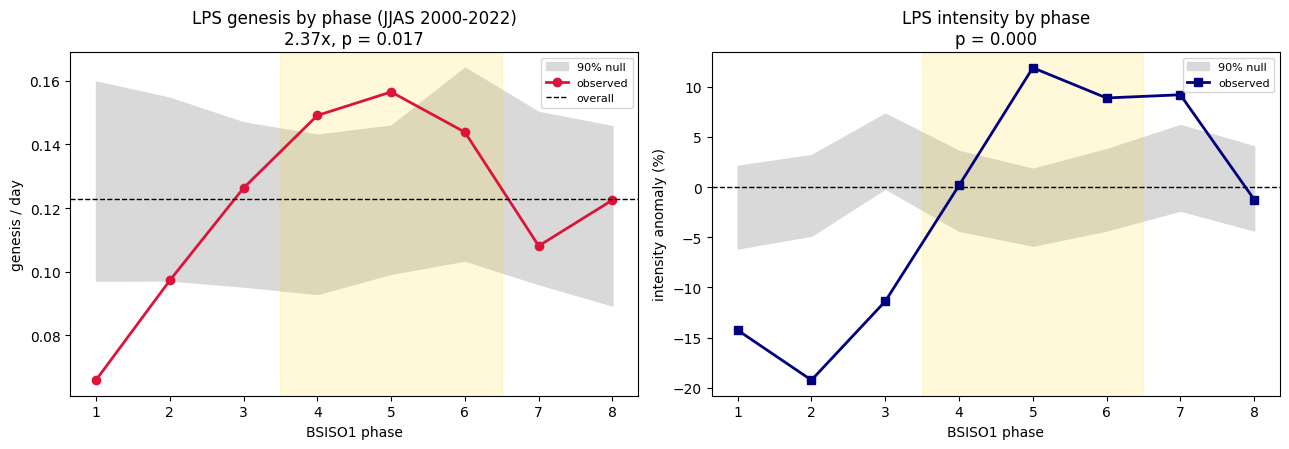

In [11]:
import matplotlib.pyplot as plt
x = np.arange(1,9)
fig, ax = plt.subplots(1, 2, figsize=(13,4.6))

ax[0].fill_between(x, tab["null_p05"], tab["null_p95"], color="0.85", label="90% null")
ax[0].plot(x, tab["rate_per_day"], "o-", c="crimson", lw=2, label="observed")
ax[0].axhline(overall, ls="--", c="k", lw=1, label="overall")
ax[0].set(xlabel="BSISO1 phase", ylabel="genesis / day", xticks=x,
          title=f"LPS genesis by phase (JJAS {Y0}-{Y1})\n{rate_obs.max()/rate_obs.min():.2f}x, p = {p_gen:.3f}")

ax[1].fill_between(x, itab["null_p05_%"], itab["null_p95_%"], color="0.85", label="90% null")
ax[1].plot(x, itab["anom_%"], "s-", c="navy", lw=2, label="observed")
ax[1].axhline(0, ls="--", c="k", lw=1)
ax[1].set(xlabel="BSISO1 phase", ylabel="intensity anomaly (%)", xticks=x,
          title=f"LPS intensity by phase\np = {p_int:.3f}")

for a in ax:
    a.axvspan(3.5, 6.5, color="gold", alpha=0.15)   # India-facing phases 4-6
    a.legend(fontsize=8)
plt.tight_layout(); plt.savefig("/kaggle/working/K_F1_genesis_intensity_by_phase.png", dpi=150)
plt.show()

The genesis peaks in phases 4,5 and the lps intensity peaks in phases 5,6,7. A lag??

BSISO amplitude and LPS genesis link


In [12]:
import numpy as np
import pandas as pd

AMP_EDGES  = [0, 1.0, 1.5, 2.0, np.inf]              # same edges as the original stage8c
AMP_LABELS = ["<1", "1-1.5", "1.5-2", ">=2"]
C_EDGES    = [0, 1.0, 1.5, np.inf]                   # panel c: fewer storms per bin -> 3 bins
C_LABELS   = ["<1", "1-1.5", ">=1.5"]
NB, NC = len(AMP_LABELS), len(C_LABELS)
FAV, UNF = [4, 5, 6], [1, 2]                         # India-facing phases vs suppressed phases
N_PERM = 1000                                        # use 300 while debugging
RNG = np.random.default_rng(20260924)


def amp_bin(a, edges=AMP_EDGES):
    return np.digitize(a, edges[1:-1])


def corr(x, y):
    return np.corrcoef(x, y)[0, 1] if len(x) > 2 else np.nan


def track_level(s, col="strength"):
    """One row per storm: its mean BSISO amplitude and mean <col> over its storm-days."""
    g = s.groupby("track").agg(amp=("amp", "mean"), y=(col, "mean")).dropna()
    return g["amp"].values, g["y"].values


def bin_means(am, y, edges, nb):
    b = amp_bin(am, edges)
    return np.array([y[b == k].mean() if (b == k).any() else np.nan for k in range(nb)])


def storm_stats(s):
    """s = storm-days with phase, amp, strength (no NaN)."""
    am, y = track_level(s)
    out = dict(r=corr(am, y), bin=bin_means(am, y, AMP_EDGES, NB))

    # phase held fixed: subtract each phase's mean strength first, THEN average per storm
    s = s.assign(resid=s["strength"] - s.groupby("phase")["strength"].transform("mean"))
    a2, y2 = track_level(s, "resid")
    out["r_pc"] = corr(a2, y2)

    for nm, ph in (("fav", FAV), ("unf", UNF)):
        a3, y3 = track_level(s[s["phase"].isin(ph)])
        out["r_" + nm] = corr(a3, y3) if len(a3) > 8 else np.nan
        out["c_" + nm] = bin_means(a3, y3, C_EDGES, NC)

    # storm-day phase x amplitude grid (for the heat map only)
    ph_, b_, st_ = s["phase"].values.astype(int), amp_bin(s["amp"].values), s["strength"].values
    grid = np.full((8, NB), np.nan)
    for p in range(1, 9):
        for k in range(NB):
            m = (ph_ == p) & (b_ == k)
            if m.any():
                grid[p - 1, k] = st_[m].mean()
    out["grid"] = grid
    return out


day_amp = season_days["amp"].values
days_per_bin = np.bincount(amp_bin(day_amp), minlength=NB)


def genesis_stats(g):
    """g = one row per storm (its genesis day) with date and amp."""
    cnt = np.bincount(amp_bin(g["amp"].values), minlength=NB)
    per_day = g.groupby("date").size().reindex(season_days["date"]).fillna(0).values
    return dict(cnt=cnt, rate=cnt / days_per_bin, r=corr(day_amp, per_day))


# ---- observed ----
sd_obs = lps.dropna(subset=["phase", "amp", "strength"])
gen9 = lps.sort_values("date").drop_duplicates("track").dropna(subset=["amp"])
obs = storm_stats(sd_obs)
obs_g = genesis_stats(gen9)
tr_amp, tr_str = track_level(sd_obs)
ref = tr_str.mean()                                   # mean of storm means (as in stage8c)
print(f"storms {len(tr_amp)} | storm-days {len(sd_obs):,} | BSISO days {len(season_days):,}")
print("BSISO days per amplitude bin:", dict(zip(AMP_LABELS, map(int, days_per_bin))))

# ---- null: every storm moved rigidly to a random year (same calendar date) ----
base = lps[["track", "date", "strength"]]
null = {k: [] for k in ("bin", "r", "r_pc", "r_fav", "r_unf", "grid", "g_rate", "g_r")}
for i in range(N_PERM):
    sh = attach_phase(redate_tracks(base, RNG, years), bsiso)
    s = sh.dropna(subset=["phase", "amp", "strength"])
    st = storm_stats(s)
    gs = genesis_stats(sh.sort_values("date").drop_duplicates("track").dropna(subset=["amp"]))
    for k in ("bin", "r", "r_pc", "r_fav", "r_unf", "grid"):
        null[k].append(st[k])
    null["g_rate"].append(gs["rate"])
    null["g_r"].append(gs["r"])
    if (i + 1) % 200 == 0:
        print(f"  permutation {i + 1}/{N_PERM}")
null = {k: np.array(v) for k, v in null.items()}


def p2(o, n):
    """Two-sided, centred on the null MEAN (trap 16), add-one so p is never exactly 0."""
    n = n[~np.isnan(n)]
    c = n.mean()
    return (1 + np.sum(np.abs(n - c) >= abs(o - c))) / (len(n) + 1)


d_obs = obs["r_fav"] - obs["r_unf"]
d_null = null["r_fav"] - null["r_unf"]
res = {                       # name: (observed, null draws, p, value quoted in blueprint 3.8)
    "r(amp, strength)":              (obs["r"],   null["r"],   p2(obs["r"], null["r"]),     0.142),
    "r(amp, strength | phase fixed)": (obs["r_pc"], null["r_pc"], p2(obs["r_pc"], null["r_pc"]), None),
    "r in phases 4-6":               (obs["r_fav"], null["r_fav"], p2(obs["r_fav"], null["r_fav"]), 0.243),
    "r in phases 1-2":               (obs["r_unf"], null["r_unf"], p2(obs["r_unf"], null["r_unf"]), -0.308),
    "interaction (4-6) - (1-2)":     (d_obs, d_null, p2(d_obs, d_null), 0.551),
    "r(daily amplitude, genesis)":   (obs_g["r"], null["g_r"], p2(obs_g["r"], null["g_r"]), -0.010),
}
print("done.")

storms 345 | storm-days 2,232 | BSISO days 2,806
BSISO days per amplitude bin: {'<1': 936, '1-1.5': 748, '1.5-2': 643, '>=2': 479}
  permutation 200/1000
  permutation 400/1000
  permutation 600/1000
  permutation 800/1000
  permutation 1000/1000
done.


In [13]:
print("=" * 82)
print("RESULT A  BSISO amplitude vs STORM STRENGTH   (strength = -min_streamfn, one value per storm)")
print("=" * 82)
nA = np.bincount(amp_bin(tr_amp), minlength=NB)
tabA = pd.DataFrame({
    "storms": nA,
    "mean_strength": obs["bin"],
    "anom_%": 100 * (obs["bin"] / ref - 1),
    "null_p05_%": 100 * (np.nanpercentile(null["bin"], 5, axis=0) / ref - 1),
    "null_p95_%": 100 * (np.nanpercentile(null["bin"], 95, axis=0) / ref - 1),
}, index=pd.Index(AMP_LABELS, name="amplitude"))
print(tabA.round(3).to_string())

print("\n" + "-" * 82)
print(f"{'statistic':<34}{'observed':>9}{'blueprint':>10}{'null mean':>11}{'null sd':>9}{'p':>9}")
for name, (o, n, p, bp) in res.items():
    bps = f"{bp:+.3f}" if bp is not None else "   --"
    print(f"{name:<34}{o:>+9.3f}{bps:>10}{np.nanmean(n):>+11.3f}{np.nanstd(n):>9.3f}{p:>9.4f}")
print(f"\nphase held fixed keeps {100 * obs['r_pc'] / obs['r']:.0f}% of the raw r")
print(f"p-values: two-sided, centred on the null mean, add-one smoothing "
      f"(floor {1 / (N_PERM + 1):.4f}); {N_PERM} storm re-datings")
print("blueprint 3.8 p-values for reference: raw 0.012, phase-controlled 0.066, "
      "interaction <0.0001, genesis 0.599")

print("\n" + "=" * 82)
print("RESULT B  BSISO amplitude vs STORM GENESIS RATE")
print("=" * 82)
tabB = pd.DataFrame({
    "bsiso_days": days_per_bin,
    "genesis": obs_g["cnt"],
    "rate_per_day": obs_g["rate"],
    "null_p05": np.nanpercentile(null["g_rate"], 5, axis=0),
    "null_p95": np.nanpercentile(null["g_rate"], 95, axis=0),
}, index=pd.Index(AMP_LABELS, name="amplitude"))
print(tabB.round(4).to_string())

tabA.to_csv("/kaggle/working/K3_strength_by_amplitude.csv")
tabB.to_csv("/kaggle/working/K4_genesis_by_amplitude.csv")

RESULT A  BSISO amplitude vs STORM STRENGTH   (strength = -min_streamfn, one value per storm)
           storms  mean_strength  anom_%  null_p05_%  null_p95_%
amplitude                                                       
<1            101   1.394876e+07  -4.135      -3.672       3.504
1-1.5         117   1.427731e+07  -1.877      -4.231       2.053
1.5-2          85   1.506588e+07   3.542      -2.420       5.687
>=2            42   1.571540e+07   8.006      -5.697       5.343

----------------------------------------------------------------------------------
statistic                          observed blueprint  null mean  null sd        p
r(amp, strength)                     +0.142    +0.142     +0.009    0.054   0.0180
r(amp, strength | phase fixed)       +0.104        --     +0.012    0.053   0.0819
r in phases 4-6                      +0.243    +0.243     -0.057    0.070   0.0010
r in phases 1-2                      -0.307    -0.308     -0.011    0.076   0.0010
interaction (4-6)

AMPLITUDE HAS NO EFFECT ON THE STORM FORMATION

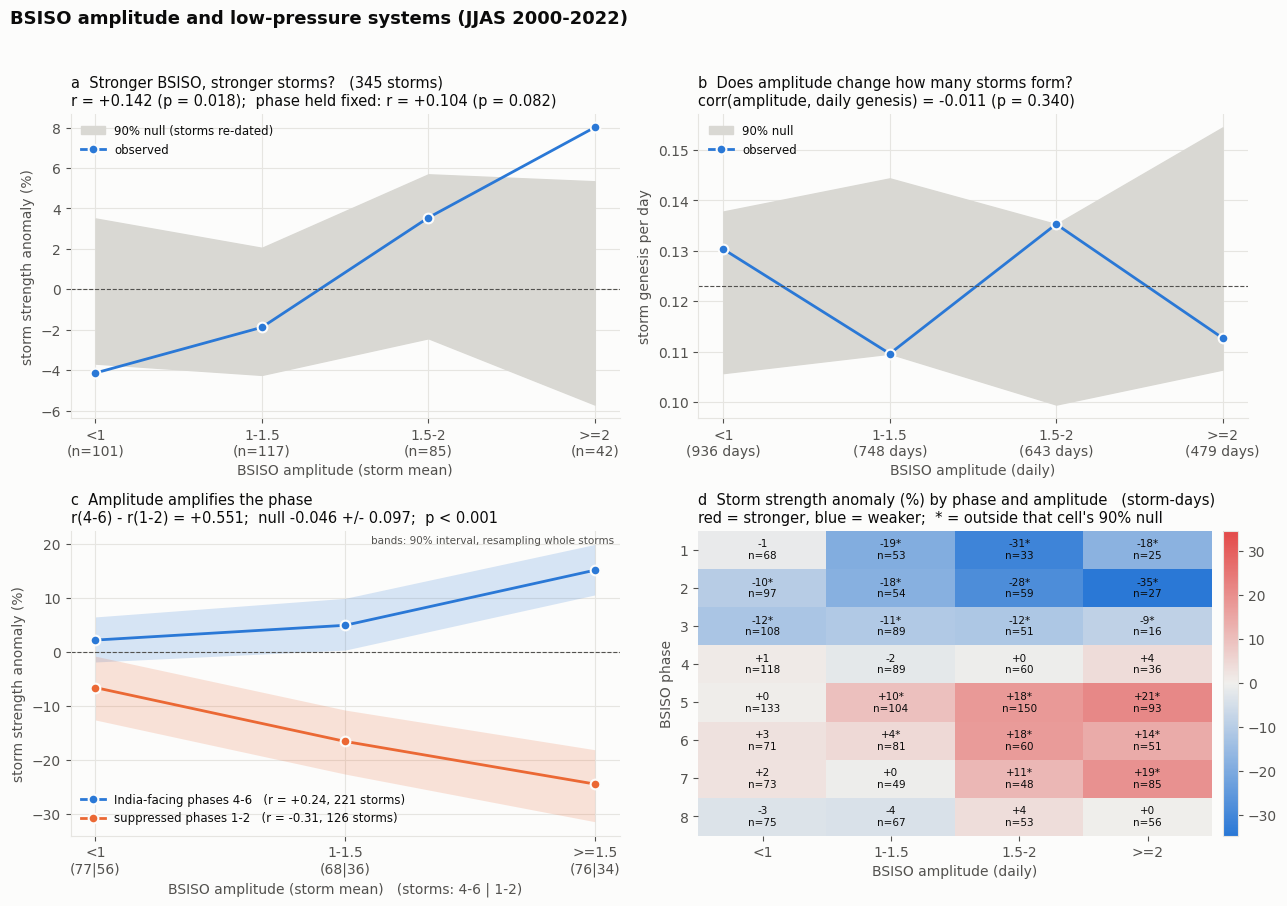

32 cells in panel d: expect ~3 starred cells by chance alone.


In [14]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
BLUE, ORANGE, RED, NEUT = "#2a78d6", "#eb6834", "#e34948", "#f0efec"
NULLC = "#d9d8d3"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})
pc = lambda v: 100 * (v / ref - 1)
fp = lambda p: (f"p < {1 / (N_PERM + 1):.3f}" if p <= 1 / (N_PERM + 1) + 1e-12 else f"p = {p:.3f}")


def boot_bins(am, y, edges, nb, nboot=1000):
    """90% interval on each bin mean, resampling WHOLE STORMS."""
    b = amp_bin(am, edges)
    n = len(am)
    W = RNG.multinomial(n, np.ones(n) / n, size=nboot)
    out = np.full((nboot, nb), np.nan)
    for k in range(nb):
        m = (b == k).astype(float)
        with np.errstate(invalid="ignore", divide="ignore"):
            out[:, k] = (W @ (y * m)) / (W @ m)
    return np.nanpercentile(out, [5, 95], axis=0)


ph_obs = sd_obs["phase"].values.astype(int)
cb_ = {}
for nm, ph in (("fav", FAV), ("unf", UNF)):
    a3, y3 = track_level(sd_obs[sd_obs["phase"].isin(ph)])
    cb_[nm] = (obs["c_" + nm], boot_bins(a3, y3, C_EDGES, NC), np.bincount(amp_bin(a3, C_EDGES), minlength=NC))

fig, ax = plt.subplots(2, 2, figsize=(13, 9.2))
x, xc = np.arange(NB), np.arange(NC)

# (a) strength vs amplitude
a = ax[0, 0]
a.fill_between(x, tabA["null_p05_%"], tabA["null_p95_%"], color=NULLC, label="90% null (storms re-dated)")
a.plot(x, tabA["anom_%"], "o-", color=BLUE, lw=2, ms=7, mec=SURF, mew=1.5, label="observed")
a.axhline(0, color=INK2, lw=0.8, ls="--")
a.set_xticks(x, [f"{l}\n(n={n})" for l, n in zip(AMP_LABELS, nA)])
a.set(xlabel="BSISO amplitude (storm mean)", ylabel="storm strength anomaly (%)")
a.set_title(f"a  Stronger BSISO, stronger storms?   ({len(tr_amp)} storms)\n"
            f"r = {obs['r']:+.3f} ({fp(res['r(amp, strength)'][2])});  "
            f"phase held fixed: r = {obs['r_pc']:+.3f} ({fp(res['r(amp, strength | phase fixed)'][2])})",
            loc="left", fontsize=10.5)
a.legend(frameon=False, fontsize=8.5, loc="upper left")

# (b) genesis vs amplitude
b_ = ax[0, 1]
b_.fill_between(x, tabB["null_p05"], tabB["null_p95"], color=NULLC, label="90% null")
b_.plot(x, tabB["rate_per_day"], "o-", color=BLUE, lw=2, ms=7, mec=SURF, mew=1.5, label="observed")
b_.axhline(obs_g["cnt"].sum() / days_per_bin.sum(), color=INK2, lw=0.8, ls="--")
b_.set_xticks(x, [f"{l}\n({n} days)" for l, n in zip(AMP_LABELS, days_per_bin)])
b_.set(xlabel="BSISO amplitude (daily)", ylabel="storm genesis per day")
b_.set_title(f"b  Does amplitude change how many storms form?\n"
             f"corr(amplitude, daily genesis) = {obs_g['r']:+.3f} ({fp(res['r(daily amplitude, genesis)'][2])})",
             loc="left", fontsize=10.5)
b_.legend(frameon=False, fontsize=8.5, loc="upper left")

# (c) the interaction: amplitude amplifies whatever the phase is doing
c = ax[1, 0]
for nm, col, lab, r_ in (("fav", BLUE, "India-facing phases 4-6", obs["r_fav"]),
                         ("unf", ORANGE, "suppressed phases 1-2", obs["r_unf"])):
    m_, ci_, n_ = cb_[nm]
    c.fill_between(xc, pc(ci_[0]), pc(ci_[1]), color=col, alpha=0.18, lw=0)
    c.plot(xc, pc(m_), "o-", color=col, lw=2, ms=7, mec=SURF, mew=1.5,
           label=f"{lab}   (r = {r_:+.2f}, {n_.sum()} storms)")
c.axhline(0, color=INK2, lw=0.8, ls="--")
c.set_xticks(xc, [f"{l}\n({a_}|{b2})" for l, a_, b2 in zip(C_LABELS, cb_["fav"][2], cb_["unf"][2])])
c.set(xlabel="BSISO amplitude (storm mean)   (storms: 4-6 | 1-2)", ylabel="storm strength anomaly (%)")
c.set_title(f"c  Amplitude amplifies the phase\nr(4-6) - r(1-2) = {d_obs:+.3f};  "
            f"null {np.nanmean(d_null):+.3f} +/- {np.nanstd(d_null):.3f};  {fp(res['interaction (4-6) - (1-2)'][2])}",
            loc="left", fontsize=10.5)
c.legend(frameon=False, fontsize=8.5, loc="best")
c.text(0.99, 0.985, "bands: 90% interval, resampling whole storms", transform=c.transAxes,
       ha="right", va="top", fontsize=7.5, color=INK2)

# (d) phase x amplitude heat map  (storm-day level)
d = ax[1, 1]
b_days = amp_bin(sd_obs["amp"].values)
grid_pc = 100 * (obs["grid"] / sd_obs["strength"].mean() - 1)
n_cell = np.zeros((8, NB), int)
for p in range(1, 9):
    for k in range(NB):
        n_cell[p - 1, k] = int(((ph_obs == p) & (b_days == k)).sum())
lo_g = 100 * (np.nanpercentile(null["grid"], 5, axis=0) / sd_obs["strength"].mean() - 1)
hi_g = 100 * (np.nanpercentile(null["grid"], 95, axis=0) / sd_obs["strength"].mean() - 1)
shown = np.where(n_cell >= 8, grid_pc, np.nan)
cmap = LinearSegmentedColormap.from_list("div", [BLUE, NEUT, RED])
lim = np.nanmax(np.abs(shown))
im = d.imshow(shown, aspect="auto", cmap=cmap, vmin=-lim, vmax=lim, origin="upper")
d.grid(False)
for p in range(8):
    for k in range(NB):
        if n_cell[p, k] < 8:
            d.text(k, p, "n<8", ha="center", va="center", fontsize=7, color=INK2)
            continue
        star = "*" if (grid_pc[p, k] < lo_g[p, k] or grid_pc[p, k] > hi_g[p, k]) else ""
        v = int(round(grid_pc[p, k])) + 0          # +0 turns -0 into 0
        d.text(k, p, f"{v:+d}{star}\nn={n_cell[p, k]}", ha="center", va="center",
               fontsize=7.5, color=INK)
d.set_xticks(x, AMP_LABELS)
d.set_yticks(range(8), [str(p) for p in range(1, 9)])
d.set(xlabel="BSISO amplitude (daily)", ylabel="BSISO phase")
d.set_title("d  Storm strength anomaly (%) by phase and amplitude   (storm-days)\n"
            "red = stronger, blue = weaker;  * = outside that cell's 90% null",
            loc="left", fontsize=10.5)
cb = fig.colorbar(im, ax=d, fraction=0.045, pad=0.02)
cb.outline.set_edgecolor(GRID)
cb.ax.tick_params(colors=INK2)
for s_ in d.spines.values():
    s_.set_visible(False)

fig.suptitle(f"BSISO amplitude and low-pressure systems (JJAS {Y0}-{Y1})", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.savefig("/kaggle/working/K_F2_amplitude_lps.png", dpi=150)
plt.show()
print("32 cells in panel d: expect ~3 starred cells by chance alone.")

wedge geometry matches the phase formula for all 8 phases


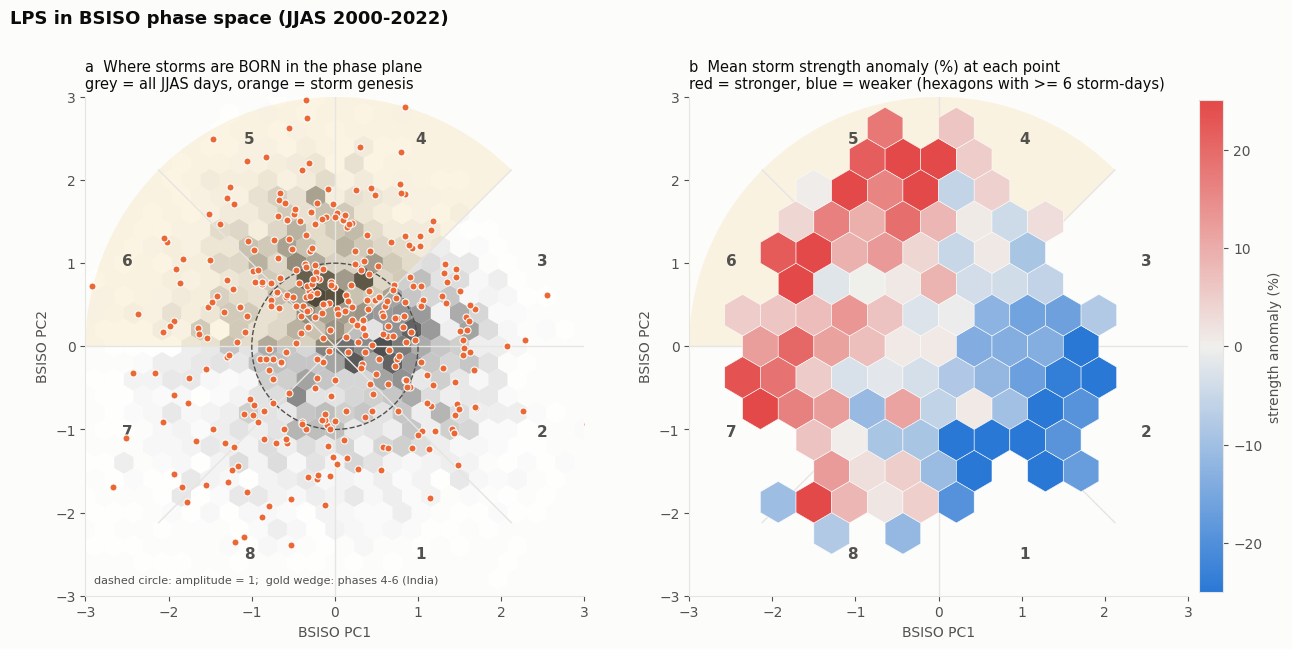

In [15]:
from matplotlib.patches import Wedge, Circle

R = 3.0


def to_xy(theta_deg, r):
    t = np.deg2rad(theta_deg)
    return r * np.sin(t), -r * np.cos(t)             # inverts theta = atan2(PC1, -PC2)


# assertion: the middle of every drawn wedge must recompute to its own phase number
for k in range(1, 9):
    px, py = to_xy((k - 0.5) * 45, 1.0)
    assert int(np.floor(np.mod(np.arctan2(px, -py), 2 * np.pi) / (np.pi / 4)) + 1) == k, "wedge geometry != phase"
print("wedge geometry matches the phase formula for all 8 phases")


def frame(a, title):
    # PC-plane angle of phase k is phi = theta - 90 deg  (math convention, from +x axis)
    a.add_patch(Wedge((0, 0), R, 45, 180, color="#eda100", alpha=0.10, lw=0))   # phases 4-6
    for k in range(8):
        a.plot(*zip((0, 0), to_xy(k * 45, R)), color=GRID, lw=1, zorder=1)
    for k in range(1, 9):
        a.text(*to_xy((k - 0.5) * 45, R * 0.9), str(k), ha="center", va="center",
               fontsize=11, color=INK2, fontweight="bold")
    a.add_patch(Circle((0, 0), 1.0, fill=False, ec=INK2, lw=1, ls="--"))
    a.set(xlim=(-R, R), ylim=(-R, R), xlabel="BSISO PC1", ylabel="BSISO PC2", aspect="equal")
    a.grid(False)
    a.set_title(title, loc="left", fontsize=10.5)


fig, ax = plt.subplots(1, 2, figsize=(13, 6.4))

a = ax[0]
frame(a, "a  Where storms are BORN in the phase plane\ngrey = all JJAS days, orange = storm genesis")
a.hexbin(season_days["pc1"], season_days["pc2"], gridsize=26, extent=(-R, R, -R, R),
         cmap="Greys", mincnt=1, linewidths=0, alpha=0.75, zorder=0)
a.scatter(gen9["pc1"], gen9["pc2"], s=26, color=ORANGE, edgecolor=SURF, linewidth=0.8, zorder=3)
a.text(-R + 0.1, -R + 0.15, "dashed circle: amplitude = 1;  gold wedge: phases 4-6 (India)",
       fontsize=8, color=INK2)

b_ = ax[1]
frame(b_, "b  Mean storm strength anomaly (%) at each point\nred = stronger, blue = weaker (hexagons with >= 6 storm-days)")
vals = 100 * (sd_obs["strength"].values / sd_obs["strength"].mean() - 1)
hb2 = b_.hexbin(sd_obs["pc1"], sd_obs["pc2"], C=vals, reduce_C_function=np.mean, gridsize=14,
                extent=(-R, R, -R, R), mincnt=6, cmap=cmap, linewidths=0.4, edgecolors=SURF,
                vmin=-25, vmax=25, zorder=2)
cb = fig.colorbar(hb2, ax=b_, fraction=0.045, pad=0.02)
cb.outline.set_edgecolor(GRID)
cb.ax.tick_params(colors=INK2)
cb.set_label("strength anomaly (%)", color=INK2)

fig.suptitle(f"LPS in BSISO phase space (JJAS {Y0}-{Y1})", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.savefig("/kaggle/working/K_F3_phase_space.png", dpi=150)
plt.show()

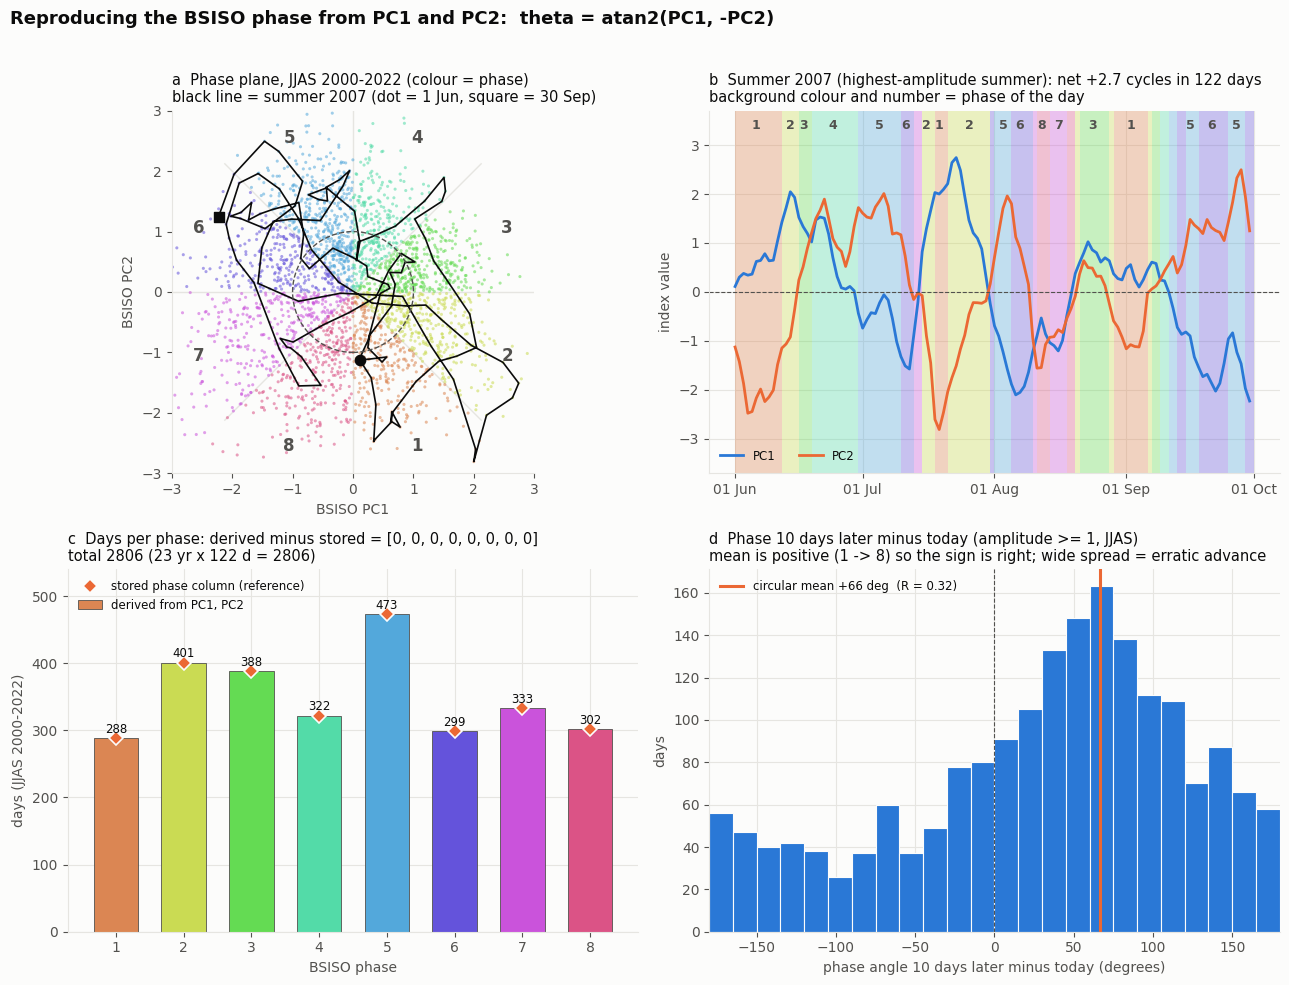

derived - stored per phase: [0, 0, 0, 0, 0, 0, 0, 0]   total 2806
mean 10-day phase advance, amp>=1: +66.3 deg  (about +6.6 deg/day), R = 0.32


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
BLUE, ORANGE, RED, NEUT = "#2a78d6", "#eb6834", "#e34948", "#f0efec"
NULLC = "#d9d8d3"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})

# phase is CYCLIC (phase 8 sits next to phase 1), so it gets a cyclic colour scale
import colorsys
PH_COL = [colorsys.hsv_to_rgb((k - 0.5) / 8, 0.62, 0.86) for k in range(1, 9)]
R = 3.0
REF = {1: 288, 2: 401, 3: 388, 4: 322, 5: 473, 6: 299, 7: 333, 8: 302}   # stored-phase counts, JJAS 2000-2022


def to_xy(theta_deg, r):
    t = np.deg2rad(theta_deg)
    return r * np.sin(t), -r * np.cos(t)         # inverts theta = atan2(PC1, -PC2)


for k in range(1, 9):                            # wedge geometry must recompute to its own phase
    px, py = to_xy((k - 0.5) * 45, 1.0)
    assert int(np.floor(np.mod(np.arctan2(px, -py), 2 * np.pi) / (np.pi / 4)) + 1) == k

jj = bsiso["date"].dt.month.between(6, 9)
b = bsiso[jj & bsiso["date"].dt.year.between(2000, 2022)].copy()
b["phase"] = b["phase"].astype(int)
# example summer = the one with the highest mean amplitude (a rule, not a hand-pick)
EX_YEAR = int(b.groupby(b["date"].dt.year)["amp"].mean().idxmax())
ex = bsiso[jj & (bsiso["date"].dt.year == EX_YEAR)].copy()
ex["phase"] = ex["phase"].astype(int)
net_cycles = np.degrees(np.angle(np.exp(1j * np.diff(ex["theta"].values)))).sum() / 360.0

fig, ax = plt.subplots(2, 2, figsize=(13, 10))

# (a) the phase plane
a = ax[0, 0]
for k in range(8):
    a.plot(*zip((0, 0), to_xy(k * 45, R)), color=GRID, lw=1, zorder=1)
for k in range(1, 9):
    a.text(*to_xy((k - 0.5) * 45, R * 0.92), str(k), ha="center", va="center",
           fontsize=12, color=INK2, fontweight="bold")
a.scatter(b["pc1"], b["pc2"], s=5, c=[PH_COL[p - 1] for p in b["phase"]], alpha=0.55, lw=0, zorder=2)
a.plot(ex["pc1"], ex["pc2"], color=INK, lw=1.2, zorder=3)
a.scatter(*ex[["pc1", "pc2"]].iloc[0], s=55, color=INK, zorder=4)
a.scatter(*ex[["pc1", "pc2"]].iloc[-1], s=55, marker="s", color=INK, zorder=4)
a.add_patch(plt.Circle((0, 0), 1.0, fill=False, ec=INK2, lw=1, ls="--", zorder=3))
a.set(xlim=(-R, R), ylim=(-R, R), xlabel="BSISO PC1", ylabel="BSISO PC2", aspect="equal")
a.grid(False)
a.set_title(f"a  Phase plane, JJAS 2000-2022 (colour = phase)\nblack line = summer {EX_YEAR} "
            f"(dot = 1 Jun, square = 30 Sep)", loc="left", fontsize=10.5)

# (b) one summer as a time series
bx = ax[0, 1]
yl = np.ceil(max(ex["pc1"].abs().max(), ex["pc2"].abs().max())) + 0.7
runs = (ex["phase"] != ex["phase"].shift()).cumsum()
for _, g in ex.groupby(runs):
    p = g["phase"].iloc[0]
    bx.axvspan(g["date"].iloc[0], g["date"].iloc[-1] + pd.Timedelta(days=1),
               color=PH_COL[p - 1], alpha=0.35, lw=0)
    if len(g) >= 3:
        bx.text(g["date"].iloc[len(g) // 2], yl - 0.3, str(p), ha="center", va="center",
                fontsize=9, color=INK2, fontweight="bold")
bx.plot(ex["date"], ex["pc1"], color=BLUE, lw=2, label="PC1")
bx.plot(ex["date"], ex["pc2"], color=ORANGE, lw=2, label="PC2")
bx.axhline(0, color=INK2, lw=0.8, ls="--")
bx.set_ylim(-yl, yl)
bx.xaxis.set_major_locator(mdates.MonthLocator())
bx.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
bx.set(ylabel="index value")
bx.set_title(f"b  Summer {EX_YEAR} (highest-amplitude summer): net {net_cycles:+.1f} cycles in 122 days\n"
             "background colour and number = phase of the day", loc="left", fontsize=10.5)
bx.legend(frameon=False, fontsize=8.5, loc="lower left", ncol=2)

# (c) phase-day counts vs the stored-phase reference
cx = ax[1, 0]
got = b["phase"].value_counts().reindex(range(1, 9), fill_value=0)
xs = np.arange(1, 9)
cx.bar(xs, got.values, color=[PH_COL[k - 1] for k in xs], width=0.66, edgecolor=INK2, linewidth=0.6,
       label="derived from PC1, PC2")
cx.plot(xs, [REF[k] for k in xs], "D", color=ORANGE, ms=7, mec=SURF, mew=1.2, ls="none",
        label="stored phase column (reference)")
for k in xs:
    cx.text(k, got[k] + 8, str(got[k]), ha="center", fontsize=8.5, color=INK)
diff = [int(got[k] - REF[k]) for k in xs]
cx.set_xticks(xs)
cx.set(xlabel="BSISO phase", ylabel="days (JJAS 2000-2022)", ylim=(0, 540))
cx.set_title(f"c  Days per phase: derived minus stored = {diff}\n"
             f"total {int(got.sum())} (23 yr x 122 d = 2806)", loc="left", fontsize=10.5)
cx.legend(frameon=False, fontsize=8.5, loc="upper left")

# (d) the phase advances: phase 10 days later minus phase today
dx = ax[1, 1]
th = bsiso.set_index("date")["theta"]
am = bsiso.set_index("date")["amp"]
fut = th.copy()
fut.index = fut.index - pd.Timedelta(days=10)                 # value at t now holds theta(t + 10)
dth = fut.reindex(th.index) - th
adv = pd.Series(np.degrees(np.angle(np.exp(1j * dth.values))), index=th.index)[dth.notna().values]
sel = adv.index[(adv.index.month.isin([6, 7, 8, 9])) & (adv.index.year >= 2000)
                & (adv.index.year <= 2022) & (am.reindex(adv.index) >= 1)]
vals = adv.loc[sel].values
z = np.exp(1j * np.deg2rad(vals)).mean()
mean_deg, Rbar = np.degrees(np.angle(z)), abs(z)
dx.hist(vals, bins=np.arange(-180, 181, 15), color=BLUE, edgecolor=SURF, linewidth=0.8)
dx.axvline(0, color=INK2, lw=0.8, ls="--")
dx.axvline(mean_deg, color=ORANGE, lw=2.2, label=f"circular mean {mean_deg:+.0f} deg  (R = {Rbar:.2f})")
dx.set(xlabel="phase angle 10 days later minus today (degrees)", ylabel="days", xlim=(-180, 180))
dx.set_title("d  Phase 10 days later minus today (amplitude >= 1, JJAS)\n"
             "mean is positive (1 -> 8) so the sign is right; wide spread = erratic advance",
             loc="left", fontsize=10.5)
dx.legend(frameon=False, fontsize=8.5, loc="upper left")

fig.suptitle("Reproducing the BSISO phase from PC1 and PC2:  theta = atan2(PC1, -PC2)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.965))
plt.savefig("/kaggle/working/K_F4_bsiso_phase.png", dpi=150)
plt.show()
print(f"derived - stored per phase: {diff}   total {int(got.sum())}")
print(f"mean 10-day phase advance, amp>=1: {mean_deg:+.1f} deg  (about {mean_deg / 10:+.1f} deg/day), R = {Rbar:.2f}")

IMERG DATA AND LPS LINK

In [17]:
import glob
import xarray as xr

IMERG_FILES = sorted(p for p in glob.glob("/kaggle/input/**/*.nc*", recursive=True))
print("netCDF files found:", IMERG_FILES)
IMERG_FILES = [p for p in IMERG_FILES if "imerg" in p.lower()] or IMERG_FILES
assert IMERG_FILES, "no .nc file under /kaggle/input - is the IMERG dataset attached?"

ds = xr.open_dataset(IMERG_FILES[0]) if len(IMERG_FILES) == 1 else xr.open_mfdataset(IMERG_FILES, combine="by_coords")
print(ds)


def first_of(options, names):
    return next((o for o in options if o in names), None)


var = first_of(["tp", "precipitation", "precipitationCal", "precip", "pr"], ds.data_vars) or list(ds.data_vars)[0]
latn, lonn = first_of(["lat", "latitude"], ds.coords), first_of(["lon", "longitude"], ds.coords)
timn = first_of(["time", "valid_time", "date"], ds.coords)
print(f"using variable '{var}' with dims lat='{latn}', lon='{lonn}', time='{timn}'")
da = ds[var].rename({k: v for k, v in {latn: "lat", lonn: "lon", timn: "time"}.items() if k != v})
da = da.sortby("lat").transpose("time", "lat", "lon")        # TRAP 3: IMERG latitude is stored DESCENDING
da = da.sel(time=da["time"].dt.month.isin([6, 7, 8, 9]))

rain = da.values.astype("float32")
tidx = pd.DatetimeIndex(da["time"].values).normalize()
lat, lon = da["lat"].values.astype("float64"), da["lon"].values.astype("float64")
nt, ny, nx = rain.shape
N = ny * nx
print(f"IMERG: {nt} JJAS days {tidx.min().date()} -> {tidx.max().date()} | lat {lat[0]}..{lat[-1]} | "
      f"lon {lon[0]}..{lon[-1]} | cells {N:,}")
nanfrac = float(np.isnan(rain).mean())
if nanfrac > 0:
    print(f"WARNING: {100 * nanfrac:.2f}% NaN in IMERG - filled with 0")
    rain = np.nan_to_num(rain)

# units check: JJAS mean over central India must be a few mm/DAY (mm/hr would read ~0.3)
mbox = rain[:, (lat >= 8) & (lat <= 28)][:, :, (lon >= 70) & (lon <= 90)].mean()
print(f"JJAS mean rainfall, 8-28N 70-90E = {mbox:.2f} mm/day  (expect roughly 5-9)")
assert 2 < mbox < 15, "units look wrong (mm/hr instead of mm/day?)"

# 'extreme' = at or above that cell's OWN 95th / 99th percentile of JJAS daily rain
p95 = np.empty((ny, nx), "float32")
p99 = np.empty((ny, nx), "float32")
for j in range(0, ny, 10):
    q = np.percentile(rain[:, j:j + 10, :], [95, 99], axis=0)
    p95[j:j + 10], p99[j:j + 10] = q[0], q[1]
ex95, ex99 = rain >= p95, rain >= p99
rain_f, ex95_f, ex99_f = rain.reshape(nt, N), ex95.reshape(nt, N), ex99.reshape(nt, N)
print(f"median local P95 = {np.median(p95):.1f} mm/day, median local P99 = {np.median(p99):.1f} mm/day")

# ---- storm-days on the IMERG grid ----
sdays = lps[["track", "date", "lat", "lon"]].copy()
sdays["date"] = pd.DatetimeIndex(sdays["date"]).normalize()
sdays["ti"] = tidx.get_indexer(sdays["date"])
sdays["iy"] = np.rint((sdays["lat"] - lat[0]) / (lat[1] - lat[0])).astype(int)
sdays["ix"] = np.rint((sdays["lon"] - lon[0]) / (lon[1] - lon[0])).astype(int)
ok = (sdays["ti"] >= 0) & sdays["iy"].between(0, ny - 1) & sdays["ix"].between(0, nx - 1)
print(f"storm-days {len(sdays):,}: usable {int(ok.sum()):,}, dropped {int((~ok).sum())} "
      f"(no IMERG day, or centre off the IMERG grid)")
sdays = sdays[ok].reset_index(drop=True)
ns = len(sdays)

# ---- distance from each storm centre to every cell, in 100 km bins out to 2000 km ----
NR = 20                                                   # bins 0-100, ..., 1900-2000 km;  bin NR = farther
lat_r, lon_r = np.deg2rad(np.repeat(lat, nx)), np.deg2rad(np.tile(lon, ny))   # row-major = (lat, lon)


def hav_km(la, lo):
    a = np.sin((lat_r - la) / 2) ** 2 + np.cos(la) * np.cos(lat_r) * np.sin((lon_r - lo) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))


D = np.empty((ns, N), np.uint8)
for i, (la, lo) in enumerate(zip(np.deg2rad(sdays["lat"].values), np.deg2rad(sdays["lon"].values))):
    D[i] = np.minimum((hav_km(la, lo) // 100).astype(np.int64), NR)
n_in_bin = np.bincount(D.ravel(), minlength=NR + 1)       # cell-days per distance bin (fixed)
centre_km = np.arange(NR) * 100 + 50

# ---- the null: each STORM moved to a different year, same calendar date, SAME position ----
NULL_YEARS = np.asarray(years)
_trk = sdays["track"].values
_ut, _inv = np.unique(_trk, return_inverse=True)
_first_year = sdays.groupby("track")["date"].first().dt.year.reindex(_ut).values
_dy, _dm, _dd = sdays["date"].dt.year.values, sdays["date"].dt.month.values, sdays["date"].dt.day.values
_kpos = np.searchsorted(NULL_YEARS, _first_year)


def redate_ti(rng):
    """New IMERG day index for every storm-day (a different year for each storm)."""
    new_year = NULL_YEARS[(_kpos + rng.integers(1, len(NULL_YEARS), len(_ut))) % len(NULL_YEARS)]
    shift = (new_year - _first_year)[_inv]
    nd = pd.to_datetime({"year": _dy + shift, "month": _dm, "day": _dd})
    t = tidx.get_indexer(pd.DatetimeIndex(nd))
    assert (t >= 0).all(), "re-dated day missing from IMERG"
    return t


RNG2 = np.random.default_rng(20261011)
print("ready.")

netCDF files found: ['/kaggle/input/datasets/divyanshyecho/imerge-2000-2024-daily/imerg_india_025_jjas_2000_2024.nc']
<xarray.Dataset> Size: 277MB
Dimensions:  (time: 3050, lat: 141, lon: 161)
Coordinates:
  * time     (time) datetime64[ns] 24kB 2000-06-01 2000-06-02 ... 2024-09-30
  * lat      (lat) float32 564B 40.0 39.75 39.5 39.25 39.0 ... 5.75 5.5 5.25 5.0
  * lon      (lon) float32 644B 60.0 60.25 60.5 60.75 ... 99.25 99.5 99.75 100.0
Data variables:
    tp       (time, lat, lon) float32 277MB ...
using variable 'tp' with dims lat='lat', lon='lon', time='time'
IMERG: 3050 JJAS days 2000-06-01 -> 2024-09-30 | lat 5.0..40.0 | lon 60.0..100.0 | cells 22,701
JJAS mean rainfall, 8-28N 70-90E = 8.28 mm/day  (expect roughly 5-9)
median local P95 = 19.5 mm/day, median local P99 = 46.5 mm/day
storm-days 2,232: usable 2,232, dropped 0 (no IMERG day, or centre off the IMERG grid)
ready.


 km from centre  rain obs    null  ratio    P(>P95) obs    null  ratio    P(>P99) obs    null  ratio
      0-100         22.98    9.66   2.38          0.187   0.055   3.41         0.0559  0.0113   4.94
    100-200         23.75    9.60   2.48          0.191   0.054   3.51         0.0630  0.0113   5.57
    200-300         21.89    9.59   2.28          0.172   0.054   3.19         0.0565  0.0112   5.06
    300-400         18.23    9.51   1.92          0.144   0.053   2.69         0.0414  0.0110   3.75
    400-500         14.81    9.33   1.59          0.114   0.053   2.17         0.0281  0.0109   2.59
    600-700         10.41    8.72   1.20          0.075   0.052   1.44         0.0140  0.0104   1.35
    900-1000         7.30    7.59   0.96          0.055   0.054   1.02         0.0099  0.0103   0.95
   1400-1500         5.23    5.76   0.91          0.049   0.053   0.92         0.0085  0.0097   0.88
   1900-2000         3.89    4.21   0.92          0.049   0.053   0.91         0.0084  0.00

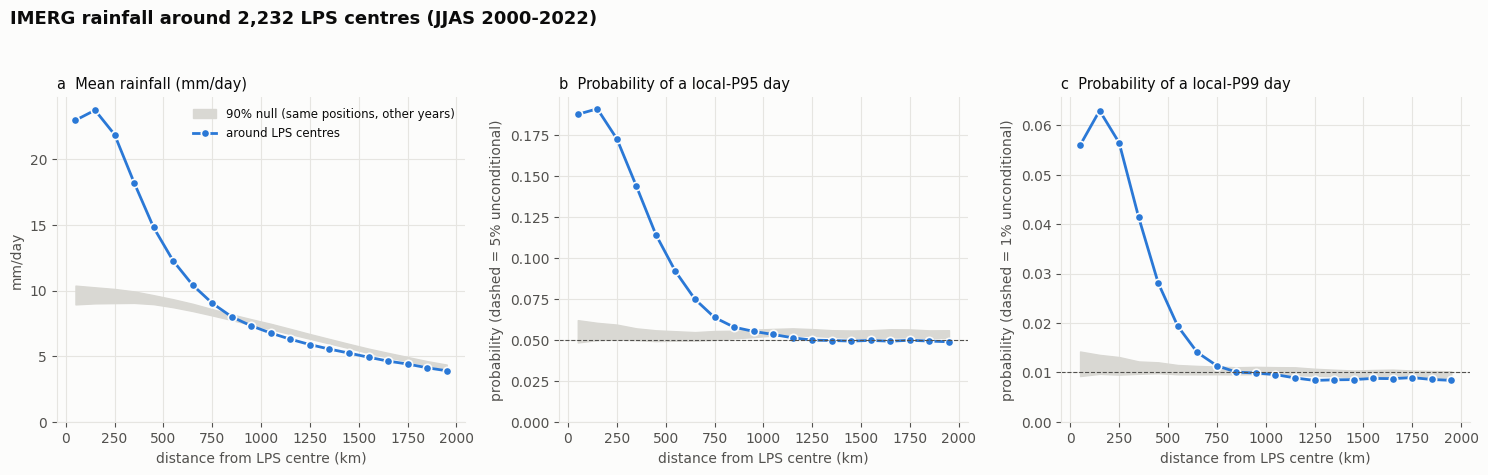

In [18]:
N_NULL_PROF = 100                                          # use 30 while debugging


def profile(ti_vec, chunk=400):
    s = np.zeros((3, NR + 1))
    for a_ in range(0, ns, chunk):
        d = D[a_:a_ + chunk].ravel()
        t = ti_vec[a_:a_ + chunk]
        s[0] += np.bincount(d, weights=rain_f[t].ravel(), minlength=NR + 1)
        s[1] += np.bincount(d, weights=ex95_f[t].ravel(), minlength=NR + 1)
        s[2] += np.bincount(d, weights=ex99_f[t].ravel(), minlength=NR + 1)
    return s[:, :NR] / n_in_bin[:NR]


prof_obs = profile(sdays["ti"].values)
prof_null = np.array([profile(redate_ti(RNG2)) for _ in range(N_NULL_PROF)])
nm = prof_null.mean(axis=0)
lo5, hi95 = np.percentile(prof_null, [5, 95], axis=0)

print(f"{'km from centre':>15}{'rain obs':>10}{'null':>8}{'ratio':>7}   {'P(>P95) obs':>12}{'null':>8}{'ratio':>7}   "
      f"{'P(>P99) obs':>12}{'null':>8}{'ratio':>7}")
for k in (0, 1, 2, 3, 4, 6, 9, 14, 19):
    print(f"{k * 100:>7}-{k * 100 + 100:<7}{prof_obs[0, k]:>10.2f}{nm[0, k]:>8.2f}{prof_obs[0, k] / nm[0, k]:>7.2f}   "
          f"{prof_obs[1, k]:>12.3f}{nm[1, k]:>8.3f}{prof_obs[1, k] / nm[1, k]:>7.2f}   "
          f"{prof_obs[2, k]:>12.4f}{nm[2, k]:>8.4f}{prof_obs[2, k] / nm[2, k]:>7.2f}")
print(f"\nnull = same {ns:,} storm positions, rainfall taken from the same date in a different year "
      f"({N_NULL_PROF} draws)")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.8))
titles = ["a  Mean rainfall (mm/day)", "b  Probability of a local-P95 day", "c  Probability of a local-P99 day"]
base_line = [None, 0.05, 0.01]
for j in range(3):
    a_ = ax[j]
    a_.fill_between(centre_km, lo5[j], hi95[j], color=NULLC, label="90% null (same positions, other years)")
    a_.plot(centre_km, prof_obs[j], "o-", color=BLUE, lw=2, ms=6, mec=SURF, mew=1.2, label="around LPS centres")
    if base_line[j]:
        a_.axhline(base_line[j], color=INK2, lw=0.8, ls="--")
    a_.set_xlabel("distance from LPS centre (km)")
    a_.set_title(titles[j], loc="left", fontsize=10.5)
    a_.set_ylim(bottom=0)
ax[0].set_ylabel("mm/day")
ax[1].set_ylabel("probability (dashed = 5% unconditional)")
ax[2].set_ylabel("probability (dashed = 1% unconditional)")
ax[0].legend(frameon=False, fontsize=8.5, loc="upper right")
fig.suptitle(f"IMERG rainfall around {ns:,} LPS centres (JJAS {Y0}-{Y1})", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.savefig("/kaggle/working/K_F5_rain_near_lps.png", dpi=150)
plt.show()

pd.DataFrame({"km_lo": np.arange(NR) * 100, "rain_obs": prof_obs[0], "rain_null": nm[0],
              "p95_obs": prof_obs[1], "p95_null": nm[1], "p99_obs": prof_obs[2], "p99_null": nm[2]}
             ).to_csv("/kaggle/working/K5_rain_vs_distance.csv", index=False)

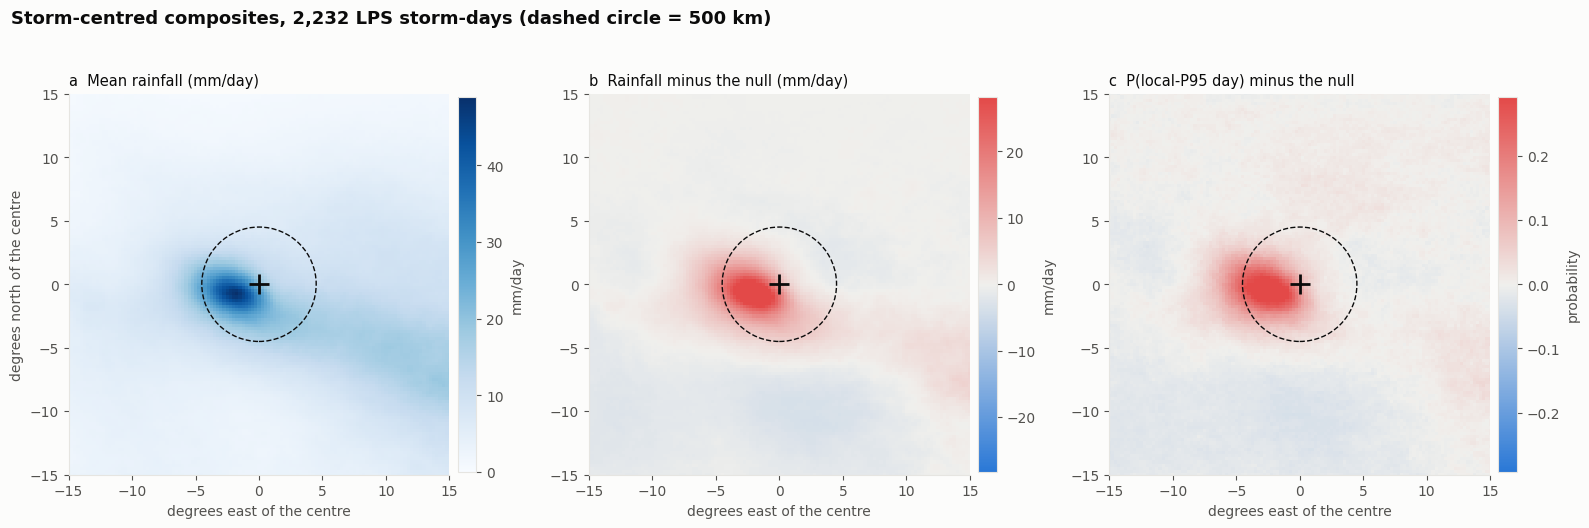

In [19]:
H = 60                                                     # 60 cells x 0.25 deg = 15 deg
K_NULL_MAP = 30                                            # use 8 while debugging


def window_sum(arr, ti_vec):
    S = np.zeros((2 * H + 1, 2 * H + 1))
    for t, y, x in zip(ti_vec, sdays["iy"].values, sdays["ix"].values):
        y0, y1, x0, x1 = max(y - H, 0), min(y + H + 1, ny), max(x - H, 0), min(x + H + 1, nx)
        S[y0 - (y - H):y1 - (y - H), x0 - (x - H):x1 - (x - H)] += arr[t, y0:y1, x0:x1]
    return S


C = np.zeros((2 * H + 1, 2 * H + 1))                       # how many storm-days cover each offset
for y, x in zip(sdays["iy"].values, sdays["ix"].values):
    y0, y1, x0, x1 = max(y - H, 0), min(y + H + 1, ny), max(x - H, 0), min(x + H + 1, nx)
    C[y0 - (y - H):y1 - (y - H), x0 - (x - H):x1 - (x - H)] += 1
Cs = np.where(C >= 50, C, np.nan)                          # hide offsets covered by < 50 storm-days

t_obs = sdays["ti"].values
rain_obs, p95_obs = window_sum(rain, t_obs) / Cs, window_sum(ex95, t_obs) / Cs
nr_, n95_ = np.zeros_like(rain_obs), np.zeros_like(p95_obs)
for _ in range(K_NULL_MAP):
    tn = redate_ti(RNG2)
    nr_ += window_sum(rain, tn) / Cs
    n95_ += window_sum(ex95, tn) / Cs
rain_null, p95_null = nr_ / K_NULL_MAP, n95_ / K_NULL_MAP

off = (np.arange(-H, H + 1)) * 0.25
fig, ax = plt.subplots(1, 3, figsize=(16, 5.2))
panels = [
    (rain_obs, "Blues", 0, None, "a  Mean rainfall (mm/day)", "mm/day"),
    (rain_obs - rain_null, "div", None, "sym", "b  Rainfall minus the null (mm/day)", "mm/day"),
    (p95_obs - p95_null, "div", None, "sym", "c  P(local-P95 day) minus the null", "probability"),
]
from matplotlib.colors import LinearSegmentedColormap
dv = LinearSegmentedColormap.from_list("div", [BLUE, NEUT, RED])
for a_, (f, cm, vmin, mode, ttl, lab) in zip(ax, panels):
    if mode == "sym":
        lim = np.nanpercentile(np.abs(f), 99.5)
        im = a_.pcolormesh(off, off, f, cmap=dv, vmin=-lim, vmax=lim, shading="auto")
    else:
        im = a_.pcolormesh(off, off, f, cmap=cm, vmin=vmin, shading="auto")
    a_.plot(0, 0, "+", color=INK, ms=14, mew=2)
    a_.add_patch(plt.Circle((0, 0), 500 / 111.0, fill=False, ec=INK, lw=1, ls="--"))
    a_.set(xlabel="degrees east of the centre", aspect="equal", xlim=(-H * .25, H * .25), ylim=(-H * .25, H * .25))
    a_.grid(False)
    a_.set_title(ttl, loc="left", fontsize=10.5)
    cb = fig.colorbar(im, ax=a_, fraction=0.046, pad=0.02)
    cb.outline.set_edgecolor(GRID)
    cb.set_label(lab, color=INK2)
ax[0].set_ylabel("degrees north of the centre")
fig.suptitle(f"Storm-centred composites, {ns:,} LPS storm-days (dashed circle = 500 km)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.savefig("/kaggle/working/K_F6_rain_composites.png", dpi=150)
plt.show()

  radius |  area % | P95 days %   (null) | P99 days %   (null) |  rain %   (null) | P99 enrichment       null 5-95%       p
   300km |     1.4 |        4.4      1.3 |        8.0      1.5 |     5.6      2.3 |           5.85     0.96-1.30     0.010
   500km |     3.8 |        9.8      3.3 |       16.1      3.8 |    12.6      5.9 |           4.28     0.98-1.20     0.010
  1000km |    14.6 |       22.3     11.8 |       29.1     13.2 |    30.2     19.1 |           2.00     0.98-1.12     0.010

'enrichment' = share of P99 days in the near zone / share of all cell-days in the near zone (1.0 = no clustering).
null = the same storm positions, but on the same date in a different year.


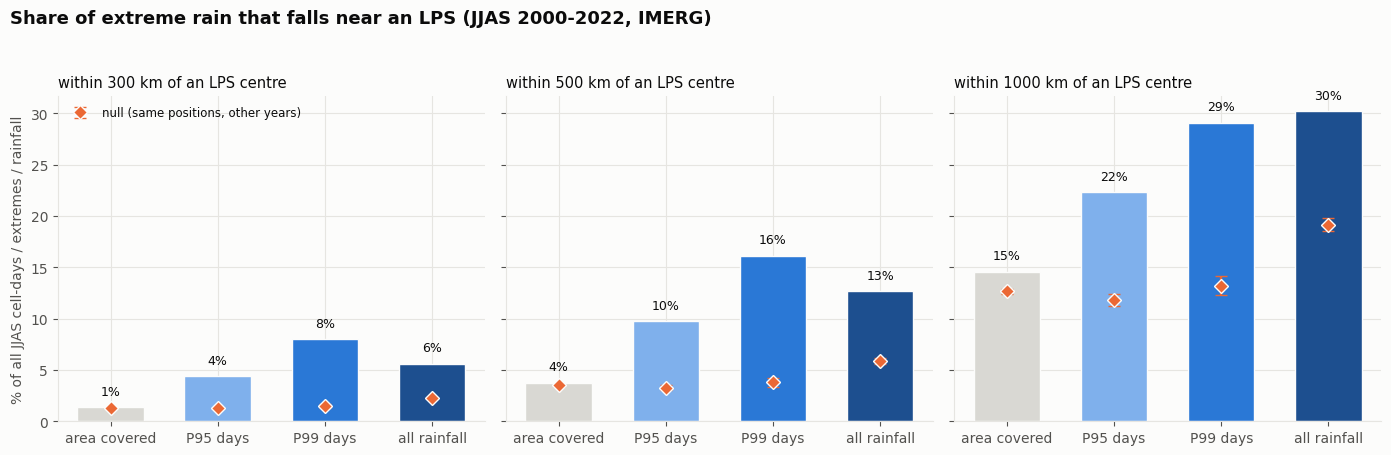

In [20]:
RADII = (300, 500, 1000)                                   # km
N_NULL_ABUND = 100                                         # use 30 while debugging
tmask_rows = np.where(tidx.year.isin(NULL_YEARS))[0]       # every JJAS day of the catalogue years
n_cells_total = len(tmask_rows) * N
tot_ex95 = int(ex95_f[tmask_rows].sum())
tot_ex99 = int(ex99_f[tmask_rows].sum())
tot_rain = float(rain_f[tmask_rows].sum())


def share(ti_vec):
    """Shares of area / P95 days / P99 days / rainfall that lie within each RADIUS of an LPS centre."""
    uniq, inv = np.unique(ti_vec, return_inverse=True)
    dmin = np.full((len(uniq), N), 255, np.uint8)
    for i in range(ns):
        np.minimum(dmin[inv[i]], D[i], out=dmin[inv[i]])
    e95, e99, rr = ex95_f[uniq], ex99_f[uniq], rain_f[uniq]
    out = []
    for R_ in RADII:
        near = dmin < (R_ // 100)
        out.append([near.sum() / n_cells_total, (e95 & near).sum() / tot_ex95,
                    (e99 & near).sum() / tot_ex99, (rr * near).sum() / tot_rain])
    return np.array(out)                                   # (len(RADII), 4)


sh_obs = share(sdays["ti"].values)
sh_null = np.array([share(redate_ti(RNG2)) for _ in range(N_NULL_ABUND)])

print(f"{'radius':>8} | {'area %':>7} | {'P95 days %':>10} {'(null)':>8} | {'P99 days %':>10} {'(null)':>8} | "
      f"{'rain %':>7} {'(null)':>8} | {'P99 enrichment':>14} {'null 5-95%':>16} {'p':>7}")
for r_i, R_ in enumerate(RADII):
    enr_obs = sh_obs[r_i, 2] / sh_obs[r_i, 0]
    enr_null = sh_null[:, r_i, 2] / sh_null[:, r_i, 0]
    p = (1 + np.sum(enr_null >= enr_obs)) / (len(enr_null) + 1)
    print(f"{R_:>6}km | {100 * sh_obs[r_i, 0]:>7.1f} | {100 * sh_obs[r_i, 1]:>10.1f} {100 * sh_null[:, r_i, 1].mean():>8.1f} | "
          f"{100 * sh_obs[r_i, 2]:>10.1f} {100 * sh_null[:, r_i, 2].mean():>8.1f} | "
          f"{100 * sh_obs[r_i, 3]:>7.1f} {100 * sh_null[:, r_i, 3].mean():>8.1f} | "
          f"{enr_obs:>14.2f} {np.percentile(enr_null, 5):>8.2f}-{np.percentile(enr_null, 95):<6.2f} {p:>7.3f}")
print("\n'enrichment' = share of P99 days in the near zone / share of all cell-days in the near zone "
      "(1.0 = no clustering).\nnull = the same storm positions, but on the same date in a different year.")

fig, ax = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
labs = ["area covered", "P95 days", "P99 days", "all rainfall"]
for r_i, R_ in enumerate(RADII):
    a_ = ax[r_i]
    xs = np.arange(4)
    a_.bar(xs, 100 * sh_obs[r_i], color=[NULLC, "#7fb0ec", BLUE, "#1d4f8f"], width=0.62, edgecolor=SURF)
    a_.errorbar(xs, 100 * sh_null[:, r_i].mean(0),
                yerr=[100 * (sh_null[:, r_i].mean(0) - np.percentile(sh_null[:, r_i], 5, axis=0)),
                      100 * (np.percentile(sh_null[:, r_i], 95, axis=0) - sh_null[:, r_i].mean(0))],
                fmt="D", color=ORANGE, ms=7, mec=SURF, capsize=4, lw=1.6, label="null (same positions, other years)")
    for k in xs:
        a_.text(k, 100 * sh_obs[r_i, k] + 1.2, f"{100 * sh_obs[r_i, k]:.0f}%", ha="center", fontsize=9, color=INK)
    a_.set_xticks(xs, labs)
    a_.set_title(f"within {R_} km of an LPS centre", loc="left", fontsize=10.5)
ax[0].set_ylabel("% of all JJAS cell-days / extremes / rainfall")
ax[0].legend(frameon=False, fontsize=8.5, loc="upper left")
fig.suptitle(f"Share of extreme rain that falls near an LPS (JJAS {Y0}-{Y1}, IMERG)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.savefig("/kaggle/working/K_F7_extreme_share.png", dpi=150)
plt.show()

ALL RESULTS OF LPS AND RAIN ARE UPTO MARK. Gating the BSISO by 1 amplitude Gives stronger results about trajectory and genesis.

gate: amplitude >= 1.0
BSISO days kept   : 1,870 of 2,806 (67%)
storms kept       : 223 of 345 (65%)  (born on an active-BSISO day)
storm-days kept   : 1,489 of 2,232 (67%)
  permutation 250/1000
  permutation 500/1000
  permutation 750/1000
  permutation 1000/1000

GENESIS RATE BY PHASE  (amplitude-gated)
       active_days  genesis  rate_gated  rate_all_days  null_p05  null_p95
phase                                                                     
1              199       12      0.0603         0.0660    0.0905    0.1709
2              259       25      0.0965         0.0973    0.0888    0.1544
3              248       25      0.1008         0.1263    0.0887    0.1532
4              195       33      0.1692         0.1491    0.0821    0.1541
5              318       44      0.1384         0.1564    0.0912    0.1478
6              205       32      0.1561         0.1438    0.1024    0.1805
7              234       25      0.1068         0.1081    0.0897    0.1581
8              21

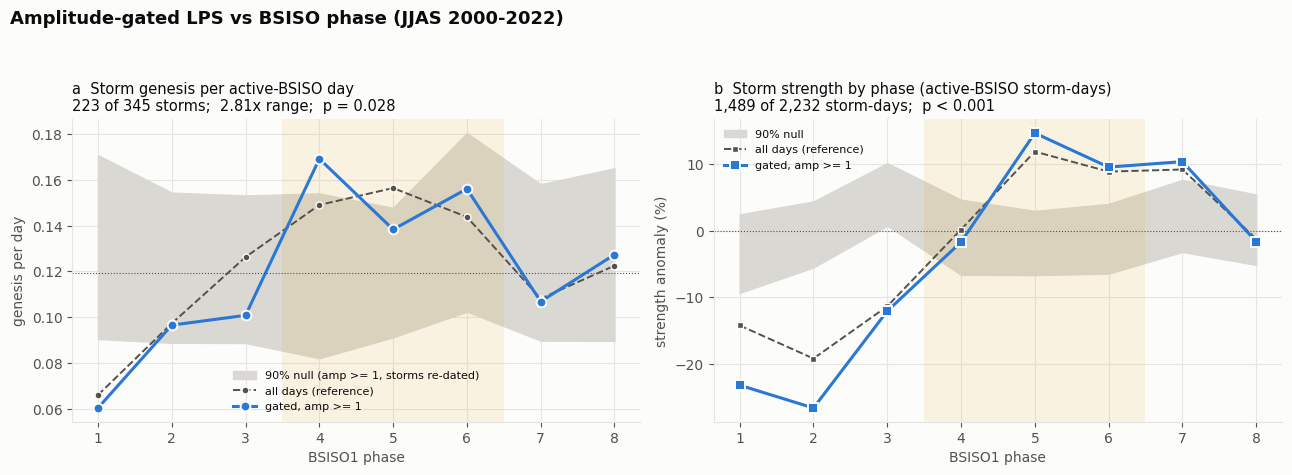

In [21]:
import numpy as np
import pandas as pd
import colorsys
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AMP_MIN = 1.0               # BSISO counts as active only when amplitude >= AMP_MIN
N_PERM = 1000               # use 300 while debugging
RNG = np.random.default_rng(20261012)

SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
BLUE, ORANGE, RED, NEUT = "#2a78d6", "#eb6834", "#e34948", "#f0efec"
NULLC = "#d9d8d3"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})
dv = LinearSegmentedColormap.from_list("div", [BLUE, NEUT, RED])
PH_COL = [colorsys.hsv_to_rgb((k - 0.5) / 8, 0.62, 0.86) for k in range(1, 9)]


def first_rows(df):
    """One row per storm: its genesis day."""
    return df.sort_values("date").drop_duplicates("track").dropna(subset=["phase", "amp"])


days_all = season_days
days_g = season_days[season_days["amp"] >= AMP_MIN]                 # DENOMINATOR is gated too
pdays_all = days_all["phase"].astype(int).value_counts().reindex(range(1, 9), fill_value=0)
pdays_g = days_g["phase"].astype(int).value_counts().reindex(range(1, 9), fill_value=0)


def genesis_curve(first, pdays):
    cnt = first["phase"].astype(int).value_counts().reindex(range(1, 9), fill_value=0)
    return cnt.values, (cnt / pdays).values, cnt.sum() / pdays.sum()


def spread(rate, overall):
    return float((((rate - overall) ** 2) / overall).sum())


def strength_curve(s):
    m = s.groupby("phase")["strength"].mean().reindex(range(1, 9))
    n = s["phase"].astype(int).value_counts().reindex(range(1, 9), fill_value=0)
    return m.values, n.values


# ---- observed: all days (reference) and gated ----
fa = first_rows(lps)
fg = fa[fa["amp"] >= AMP_MIN]
cnt_a, rate_a, ov_a = genesis_curve(fa, pdays_all)
cnt_g, rate_g, ov_g = genesis_curve(fg, pdays_g)
sa = lps.dropna(subset=["phase", "amp", "strength"])
sg = sa[sa["amp"] >= AMP_MIN]
m_a, n_a = strength_curve(sa)
m_g, n_g = strength_curve(sg)
an_a = 100 * (m_a / sa["strength"].mean() - 1)
an_g = 100 * (m_g / sg["strength"].mean() - 1)
obs_gstat, obs_sstat = spread(rate_g, ov_g), float(np.nansum((an_g / 100) ** 2))
print(f"gate: amplitude >= {AMP_MIN}")
print(f"BSISO days kept   : {len(days_g):,} of {len(days_all):,} ({100 * len(days_g) / len(days_all):.0f}%)")
print(f"storms kept       : {len(fg)} of {len(fa)} ({100 * len(fg) / len(fa):.0f}%)  (born on an active-BSISO day)")
print(f"storm-days kept   : {len(sg):,} of {len(sa):,} ({100 * len(sg) / len(sa):.0f}%)")

# ---- null: each storm moved rigidly to another year; the gate is re-applied to the shuffled dates ----
base = lps[["track", "date", "strength"]]
null = {"g_rate": [], "g_stat": [], "s_anom": [], "s_stat": []}
for i in range(N_PERM):
    sh = attach_phase(redate_tracks(base, RNG, years), bsiso)
    f = first_rows(sh)
    f = f[f["amp"] >= AMP_MIN]
    _, rt, ov = genesis_curve(f, pdays_g)
    null["g_rate"].append(rt)
    null["g_stat"].append(spread(rt, ov))
    s = sh.dropna(subset=["phase", "amp", "strength"])
    s = s[s["amp"] >= AMP_MIN]
    m, _ = strength_curve(s)
    an = m / s["strength"].mean() - 1
    null["s_anom"].append(100 * an)
    null["s_stat"].append(float(np.nansum(an ** 2)))
    if (i + 1) % 250 == 0:
        print(f"  permutation {i + 1}/{N_PERM}")
null = {k: np.array(v) for k, v in null.items()}
p_gen = (1 + np.sum(null["g_stat"] >= obs_gstat)) / (N_PERM + 1)
p_int = (1 + np.sum(null["s_stat"] >= obs_sstat)) / (N_PERM + 1)

print("\nGENESIS RATE BY PHASE  (amplitude-gated)")
tG = pd.DataFrame({
    "active_days": pdays_g.values, "genesis": cnt_g, "rate_gated": rate_g, "rate_all_days": rate_a,
    "null_p05": np.nanpercentile(null["g_rate"], 5, axis=0),
    "null_p95": np.nanpercentile(null["g_rate"], 95, axis=0),
}, index=pd.Index(range(1, 9), name="phase"))
print(tG.round(4).to_string())
print(f"max/min: gated {rate_g.max() / rate_g.min():.2f}x   all-days {rate_a.max() / rate_a.min():.2f}x   "
      f"| PERM p (gated) = {p_gen:.4f}")

print("\nSTORM STRENGTH ANOMALY BY PHASE  (amplitude-gated)")
tS = pd.DataFrame({
    "storm_days": n_g, "anom_gated_%": an_g, "anom_all_days_%": an_a,
    "null_p05_%": np.nanpercentile(null["s_anom"], 5, axis=0),
    "null_p95_%": np.nanpercentile(null["s_anom"], 95, axis=0),
}, index=pd.Index(range(1, 9), name="phase"))
print(tS.round(2).to_string())
print(f"PERM p (gated) = {p_int:.4f}   (floor {1 / (N_PERM + 1):.4f});  {N_PERM} storm re-datings, gate re-applied each time")
tG.to_csv("/kaggle/working/K8_gated_genesis_by_phase.csv")
tS.to_csv("/kaggle/working/K8_gated_intensity_by_phase.csv")

fp = lambda p: (f"p < {1 / (N_PERM + 1):.3f}" if p <= 1 / (N_PERM + 1) + 1e-12 else f"p = {p:.3f}")
x = np.arange(1, 9)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
a = ax[0]
a.fill_between(x, tG["null_p05"], tG["null_p95"], color=NULLC, label=f"90% null (amp >= {AMP_MIN:g}, storms re-dated)")
a.plot(x, rate_a, "o--", color=INK2, lw=1.4, ms=5, mec=SURF, label="all days (reference)")
a.plot(x, rate_g, "o-", color=BLUE, lw=2.2, ms=7, mec=SURF, mew=1.4, label=f"gated, amp >= {AMP_MIN:g}")
a.axhline(ov_g, color=INK2, lw=0.8, ls=":")
a.set_title(f"a  Storm genesis per active-BSISO day\n{len(fg)} of {len(fa)} storms;  "
            f"{rate_g.max() / rate_g.min():.2f}x range;  {fp(p_gen)}", loc="left", fontsize=10.5)
a.set(xlabel="BSISO1 phase", ylabel="genesis per day", xticks=x)
a.legend(frameon=False, fontsize=8, loc="lower center")
b = ax[1]
b.fill_between(x, tS["null_p05_%"], tS["null_p95_%"], color=NULLC, label="90% null")
b.plot(x, an_a, "s--", color=INK2, lw=1.4, ms=5, mec=SURF, label="all days (reference)")
b.plot(x, an_g, "s-", color=BLUE, lw=2.2, ms=7, mec=SURF, mew=1.4, label=f"gated, amp >= {AMP_MIN:g}")
b.axhline(0, color=INK2, lw=0.8, ls=":")
b.set_title(f"b  Storm strength by phase (active-BSISO storm-days)\n{len(sg):,} of {len(sa):,} storm-days;  {fp(p_int)}",
            loc="left", fontsize=10.5)
b.set(xlabel="BSISO1 phase", ylabel="strength anomaly (%)", xticks=x)
b.legend(frameon=False, fontsize=8, loc="upper left")
for a_ in ax:
    a_.axvspan(3.5, 6.5, color="#eda100", alpha=0.10, lw=0)          # India-facing phases 4-6
fig.suptitle(f"Amplitude-gated LPS vs BSISO phase (JJAS {Y0}-{Y1})", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig("/kaggle/working/K_F8_gated_genesis_intensity.png", dpi=150)
plt.show()

gated: 311 storms with >= 1 active storm-day | 1,489 storm-days | 1,870 active BSISO days
active BSISO days per amplitude bin: {'1-1.5': 748, '1.5-2': 643, '>=2': 479}
  permutation 250/1000
  permutation 500/1000
  permutation 750/1000
  permutation 1000/1000
GATED  amplitude vs STORM STRENGTH   (one value per storm, active-BSISO days only)
           storms  mean_strength  anom_%  null_p05_%  null_p95_%
amplitude                                                       
1-1.5         150   1.400139e+07  -4.616      -5.527       0.594
1.5-2         110   1.506709e+07   2.643      -2.474       3.829
>=2            51   1.583522e+07   7.876      -5.141       5.687

--------------------------------------------------------------------------------
statistic                          observed  null mean  null sd        p
r(amp, strength)                     +0.174     +0.034    0.058   0.0160
r(amp, strength | phase fixed)       +0.115     +0.038    0.057   0.1718
r in phases 4-6               

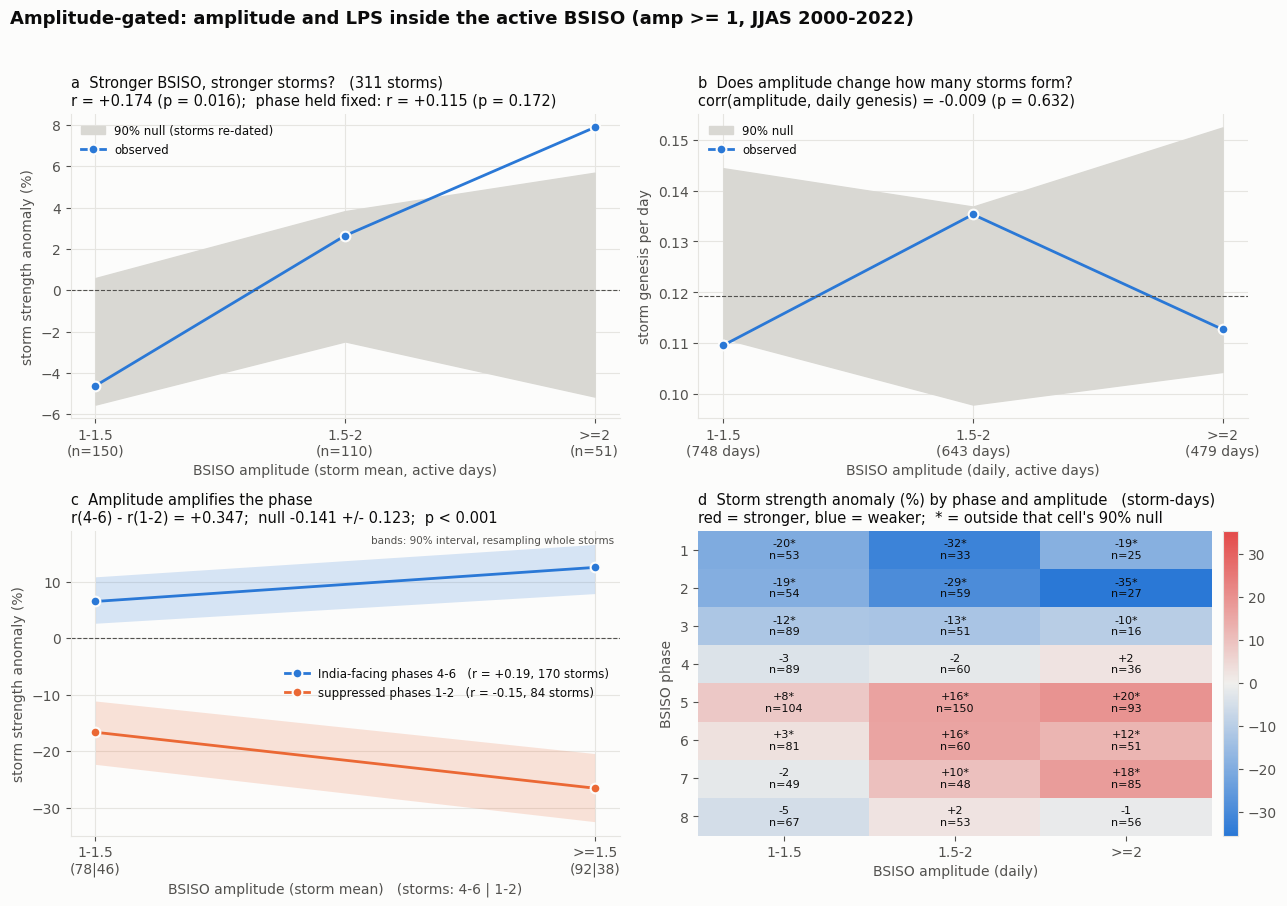

In [22]:
AMP_EDGES_G = [AMP_MIN, 1.5, 2.0, np.inf]
C_EDGES_G = [AMP_MIN, 1.5, np.inf]
lab = lambda e: [f"{lo:g}-{hi:g}" if np.isfinite(hi) else f">={lo:g}" for lo, hi in zip(e[:-1], e[1:])]
AMP_LABELS_G, C_LABELS_G = lab(AMP_EDGES_G), lab(C_EDGES_G)
NBg, NCg = len(AMP_LABELS_G), len(C_LABELS_G)
FAV, UNF = [4, 5, 6], [1, 2]


def abin(a, edges):
    return np.digitize(a, edges[1:-1])


def corr(x_, y_):
    return np.corrcoef(x_, y_)[0, 1] if len(x_) > 2 else np.nan


def track_level(s, col="strength"):
    g = s.groupby("track").agg(amp=("amp", "mean"), y=(col, "mean")).dropna()
    return g["amp"].values, g["y"].values


def bin_means(am, y, edges, nb):
    b_ = abin(am, edges)
    return np.array([y[b_ == k].mean() if (b_ == k).any() else np.nan for k in range(nb)])


def storm_stats_g(s):
    """s = storm-days that are ALREADY gated (amp >= AMP_MIN), no NaN."""
    am, y = track_level(s)
    out = dict(r=corr(am, y), bin=bin_means(am, y, AMP_EDGES_G, NBg))
    s = s.assign(resid=s["strength"] - s.groupby("phase")["strength"].transform("mean"))
    a2, y2 = track_level(s, "resid")
    out["r_pc"] = corr(a2, y2)
    for nm, ph in (("fav", FAV), ("unf", UNF)):
        a3, y3 = track_level(s[s["phase"].isin(ph)])
        out["r_" + nm] = corr(a3, y3) if len(a3) > 8 else np.nan
        out["c_" + nm] = bin_means(a3, y3, C_EDGES_G, NCg)
    ph_, b_, st_ = s["phase"].values.astype(int), abin(s["amp"].values, AMP_EDGES_G), s["strength"].values
    grid = np.full((8, NBg), np.nan)
    for p in range(1, 9):
        for k in range(NBg):
            m = (ph_ == p) & (b_ == k)
            if m.any():
                grid[p - 1, k] = st_[m].mean()
    out["grid"] = grid
    return out


act_days = season_days[season_days["amp"] >= AMP_MIN]
day_amp_g = act_days["amp"].values
days_per_bin_g = np.bincount(abin(day_amp_g, AMP_EDGES_G), minlength=NBg)


def genesis_stats_g(first_g):
    cnt = np.bincount(abin(first_g["amp"].values, AMP_EDGES_G), minlength=NBg)
    per_day = first_g.groupby("date").size().reindex(act_days["date"]).fillna(0).values
    return dict(cnt=cnt, rate=cnt / days_per_bin_g, r=corr(day_amp_g, per_day))


sd_obs = sg                                              # gated storm-days from 12A
obs = storm_stats_g(sd_obs)
obs_gs = genesis_stats_g(fg)
tr_amp, tr_str = track_level(sd_obs)
ref = tr_str.mean()
print(f"gated: {len(tr_amp)} storms with >= 1 active storm-day | {len(sd_obs):,} storm-days | "
      f"{len(act_days):,} active BSISO days")
print("active BSISO days per amplitude bin:", dict(zip(AMP_LABELS_G, map(int, days_per_bin_g))))

nullB = {k: [] for k in ("bin", "r", "r_pc", "r_fav", "r_unf", "grid", "g_rate", "g_r")}
for i in range(N_PERM):
    sh = attach_phase(redate_tracks(base, RNG, years), bsiso)
    s = sh.dropna(subset=["phase", "amp", "strength"])
    s = s[s["amp"] >= AMP_MIN]
    st = storm_stats_g(s)
    f = first_rows(sh)
    gs = genesis_stats_g(f[f["amp"] >= AMP_MIN])
    for k in ("bin", "r", "r_pc", "r_fav", "r_unf", "grid"):
        nullB[k].append(st[k])
    nullB["g_rate"].append(gs["rate"])
    nullB["g_r"].append(gs["r"])
    if (i + 1) % 250 == 0:
        print(f"  permutation {i + 1}/{N_PERM}")
nullB = {k: np.array(v) for k, v in nullB.items()}


def p2(o, n):
    """Two-sided, centred on the null MEAN (trap 16), add-one so p is never exactly 0."""
    n = n[~np.isnan(n)]
    c = n.mean()
    return (1 + np.sum(np.abs(n - c) >= abs(o - c))) / (len(n) + 1)


d_obs = obs["r_fav"] - obs["r_unf"]
d_null = nullB["r_fav"] - nullB["r_unf"]
resB = {
    "r(amp, strength)":               (obs["r"],    nullB["r"],    p2(obs["r"], nullB["r"])),
    "r(amp, strength | phase fixed)": (obs["r_pc"], nullB["r_pc"], p2(obs["r_pc"], nullB["r_pc"])),
    "r in phases 4-6":                (obs["r_fav"], nullB["r_fav"], p2(obs["r_fav"], nullB["r_fav"])),
    "r in phases 1-2":                (obs["r_unf"], nullB["r_unf"], p2(obs["r_unf"], nullB["r_unf"])),
    "interaction (4-6) - (1-2)":      (d_obs, d_null, p2(d_obs, d_null)),
    "r(daily amplitude, genesis)":    (obs_gs["r"], nullB["g_r"], p2(obs_gs["r"], nullB["g_r"])),
}
nA = np.bincount(abin(tr_amp, AMP_EDGES_G), minlength=NBg)
tabA = pd.DataFrame({
    "storms": nA, "mean_strength": obs["bin"], "anom_%": 100 * (obs["bin"] / ref - 1),
    "null_p05_%": 100 * (np.nanpercentile(nullB["bin"], 5, axis=0) / ref - 1),
    "null_p95_%": 100 * (np.nanpercentile(nullB["bin"], 95, axis=0) / ref - 1),
}, index=pd.Index(AMP_LABELS_G, name="amplitude"))
tabB = pd.DataFrame({
    "active_days": days_per_bin_g, "genesis": obs_gs["cnt"], "rate_per_day": obs_gs["rate"],
    "null_p05": np.nanpercentile(nullB["g_rate"], 5, axis=0),
    "null_p95": np.nanpercentile(nullB["g_rate"], 95, axis=0),
}, index=pd.Index(AMP_LABELS_G, name="amplitude"))

print("=" * 80)
print(f"GATED  amplitude vs STORM STRENGTH   (one value per storm, active-BSISO days only)")
print("=" * 80)
print(tabA.round(3).to_string())
print("\n" + "-" * 80)
print(f"{'statistic':<34}{'observed':>9}{'null mean':>11}{'null sd':>9}{'p':>9}")
for nm_, (o, n, p) in resB.items():
    print(f"{nm_:<34}{o:>+9.3f}{np.nanmean(n):>+11.3f}{np.nanstd(n):>9.3f}{p:>9.4f}")
print(f"\nphase held fixed keeps {100 * obs['r_pc'] / obs['r']:.0f}% of the raw r")
print("\nGATED  amplitude vs GENESIS RATE")
print(tabB.round(4).to_string())
tabA.to_csv("/kaggle/working/K9_gated_strength_by_amplitude.csv")
tabB.to_csv("/kaggle/working/K9_gated_genesis_by_amplitude.csv")

# ---- figure ----
pc = lambda v: 100 * (v / ref - 1)


def boot_bins(am, y, edges, nb, nboot=1000):
    b_ = abin(am, edges)
    n = len(am)
    W = RNG.multinomial(n, np.ones(n) / n, size=nboot)
    out = np.full((nboot, nb), np.nan)
    for k in range(nb):
        m = (b_ == k).astype(float)
        with np.errstate(invalid="ignore", divide="ignore"):
            out[:, k] = (W @ (y * m)) / (W @ m)
    return np.nanpercentile(out, [5, 95], axis=0)


ph_obs = sd_obs["phase"].values.astype(int)
cb_ = {}
for nm_, ph in (("fav", FAV), ("unf", UNF)):
    a3, y3 = track_level(sd_obs[sd_obs["phase"].isin(ph)])
    cb_[nm_] = (obs["c_" + nm_], boot_bins(a3, y3, C_EDGES_G, NCg), np.bincount(abin(a3, C_EDGES_G), minlength=NCg))

fig, ax = plt.subplots(2, 2, figsize=(13, 9.2))
xg, xc = np.arange(NBg), np.arange(NCg)

a = ax[0, 0]
a.fill_between(xg, tabA["null_p05_%"], tabA["null_p95_%"], color=NULLC, label="90% null (storms re-dated)")
a.plot(xg, tabA["anom_%"], "o-", color=BLUE, lw=2, ms=7, mec=SURF, mew=1.5, label="observed")
a.axhline(0, color=INK2, lw=0.8, ls="--")
a.set_xticks(xg, [f"{l}\n(n={n})" for l, n in zip(AMP_LABELS_G, nA)])
a.set(xlabel="BSISO amplitude (storm mean, active days)", ylabel="storm strength anomaly (%)")
a.set_title(f"a  Stronger BSISO, stronger storms?   ({len(tr_amp)} storms)\n"
            f"r = {obs['r']:+.3f} ({fp(resB['r(amp, strength)'][2])});  "
            f"phase held fixed: r = {obs['r_pc']:+.3f} ({fp(resB['r(amp, strength | phase fixed)'][2])})",
            loc="left", fontsize=10.5)
a.legend(frameon=False, fontsize=8.5, loc="upper left")

b = ax[0, 1]
b.fill_between(xg, tabB["null_p05"], tabB["null_p95"], color=NULLC, label="90% null")
b.plot(xg, tabB["rate_per_day"], "o-", color=BLUE, lw=2, ms=7, mec=SURF, mew=1.5, label="observed")
b.axhline(obs_gs["cnt"].sum() / days_per_bin_g.sum(), color=INK2, lw=0.8, ls="--")
b.set_xticks(xg, [f"{l}\n({n} days)" for l, n in zip(AMP_LABELS_G, days_per_bin_g)])
b.set(xlabel="BSISO amplitude (daily, active days)", ylabel="storm genesis per day")
b.set_title(f"b  Does amplitude change how many storms form?\n"
            f"corr(amplitude, daily genesis) = {obs_gs['r']:+.3f} ({fp(resB['r(daily amplitude, genesis)'][2])})",
            loc="left", fontsize=10.5)
b.legend(frameon=False, fontsize=8.5, loc="upper left")

c = ax[1, 0]
for nm_, col, lb, r_ in (("fav", BLUE, "India-facing phases 4-6", obs["r_fav"]),
                         ("unf", ORANGE, "suppressed phases 1-2", obs["r_unf"])):
    m_, ci_, n_ = cb_[nm_]
    c.fill_between(xc, pc(ci_[0]), pc(ci_[1]), color=col, alpha=0.18, lw=0)
    c.plot(xc, pc(m_), "o-", color=col, lw=2, ms=7, mec=SURF, mew=1.5,
           label=f"{lb}   (r = {r_:+.2f}, {n_.sum()} storms)")
c.axhline(0, color=INK2, lw=0.8, ls="--")
c.set_xticks(xc, [f"{l}\n({a_}|{b2})" for l, a_, b2 in zip(C_LABELS_G, cb_["fav"][2], cb_["unf"][2])])
c.set(xlabel="BSISO amplitude (storm mean)   (storms: 4-6 | 1-2)", ylabel="storm strength anomaly (%)")
c.set_title(f"c  Amplitude amplifies the phase\nr(4-6) - r(1-2) = {d_obs:+.3f};  "
            f"null {np.nanmean(d_null):+.3f} +/- {np.nanstd(d_null):.3f};  {fp(resB['interaction (4-6) - (1-2)'][2])}",
            loc="left", fontsize=10.5)
c.legend(frameon=False, fontsize=8.5, loc="best")
c.text(0.99, 0.985, "bands: 90% interval, resampling whole storms", transform=c.transAxes,
       ha="right", va="top", fontsize=7.5, color=INK2)

d = ax[1, 1]
b_days = abin(sd_obs["amp"].values, AMP_EDGES_G)
ref_d = sd_obs["strength"].mean()
grid_pc = 100 * (obs["grid"] / ref_d - 1)
n_cell = np.zeros((8, NBg), int)
for p in range(1, 9):
    for k in range(NBg):
        n_cell[p - 1, k] = int(((ph_obs == p) & (b_days == k)).sum())
lo_g = 100 * (np.nanpercentile(nullB["grid"], 5, axis=0) / ref_d - 1)
hi_g = 100 * (np.nanpercentile(nullB["grid"], 95, axis=0) / ref_d - 1)
shown = np.where(n_cell >= 8, grid_pc, np.nan)
lim = np.nanmax(np.abs(shown))
im = d.imshow(shown, aspect="auto", cmap=dv, vmin=-lim, vmax=lim, origin="upper")
d.grid(False)
for p in range(8):
    for k in range(NBg):
        if n_cell[p, k] < 8:
            d.text(k, p, "n<8", ha="center", va="center", fontsize=7, color=INK2)
            continue
        star = "*" if (grid_pc[p, k] < lo_g[p, k] or grid_pc[p, k] > hi_g[p, k]) else ""
        v = int(round(grid_pc[p, k])) + 0
        d.text(k, p, f"{v:+d}{star}\nn={n_cell[p, k]}", ha="center", va="center", fontsize=8, color=INK)
d.set_xticks(xg, AMP_LABELS_G)
d.set_yticks(range(8), [str(p) for p in range(1, 9)])
d.set(xlabel="BSISO amplitude (daily)", ylabel="BSISO phase")
d.set_title("d  Storm strength anomaly (%) by phase and amplitude   (storm-days)\n"
            "red = stronger, blue = weaker;  * = outside that cell's 90% null", loc="left", fontsize=10.5)
cb = fig.colorbar(im, ax=d, fraction=0.045, pad=0.02)
cb.outline.set_edgecolor(GRID)
cb.ax.tick_params(colors=INK2)
for s_ in d.spines.values():
    s_.set_visible(False)
fig.suptitle(f"Amplitude-gated: amplitude and LPS inside the active BSISO (amp >= {AMP_MIN:g}, JJAS {Y0}-{Y1})",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.savefig("/kaggle/working/K_F9_gated_amplitude.png", dpi=150)
plt.show()

wedge geometry matches the phase formula for all 8 phases


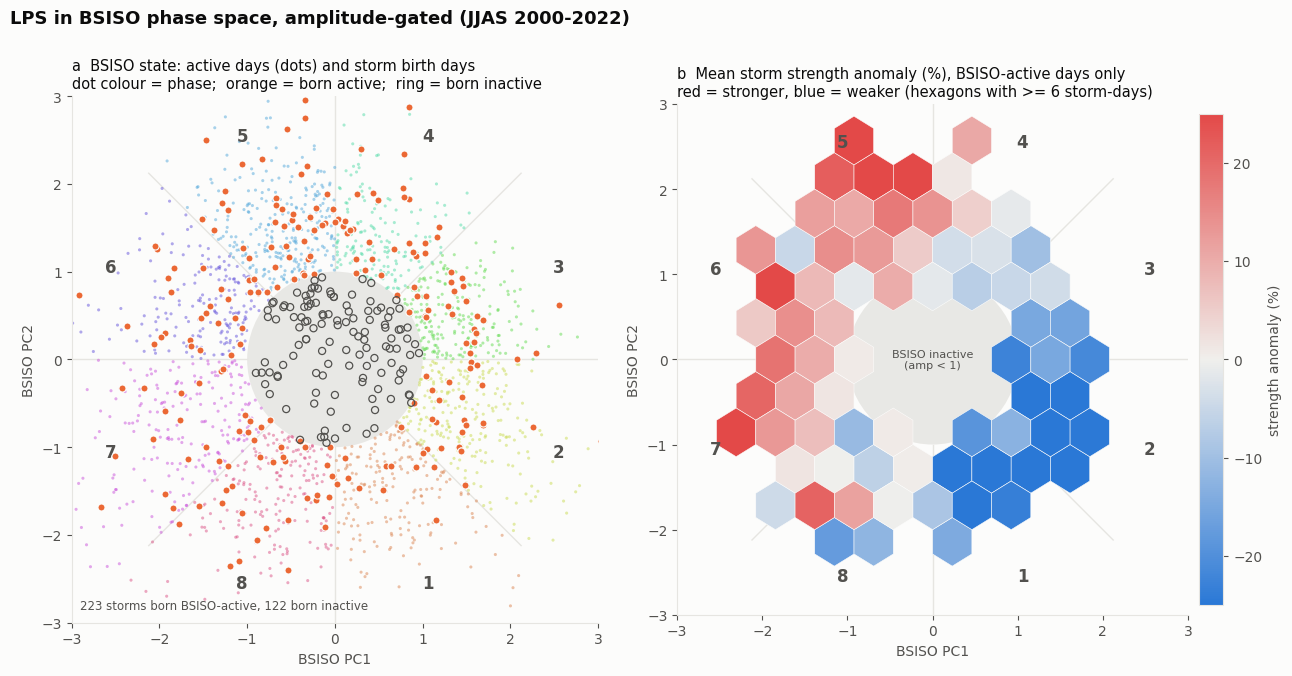

In [23]:
# "BSISO-active" = amplitude >= AMP_MIN.  It says NOTHING about storms or rainfall: a day is BSISO-active
# whether or not an LPS exists.  (Not to be confused with an ACTIVE rainfall SPELL, which is a rain index.)
# Wedges are drawn from the SAME formula as the phase, theta = atan2(PC1, -PC2), and asserted below.
R = 3.0


def to_xy(theta_deg, r):
    t = np.deg2rad(theta_deg)
    return r * np.sin(t), -r * np.cos(t)             # inverts theta = atan2(PC1, -PC2)


for k in range(1, 9):
    px, py = to_xy((k - 0.5) * 45, 1.0)
    assert int(np.floor(np.mod(np.arctan2(px, -py), 2 * np.pi) / (np.pi / 4)) + 1) == k, "wedge geometry != phase"
print("wedge geometry matches the phase formula for all 8 phases")


def frame(a, title, label_inactive=True):
    a.add_patch(plt.Circle((0, 0), AMP_MIN, color=NULLC, alpha=0.55, lw=0, zorder=0))      # BSISO inactive
    for k in range(8):
        a.plot(*zip(to_xy(k * 45, AMP_MIN), to_xy(k * 45, R)), color=GRID, lw=1, zorder=1)
    for k in range(1, 9):
        a.text(*to_xy((k - 0.5) * 45, R * 0.92), str(k), ha="center", va="center",
               fontsize=12, color=INK2, fontweight="bold")
    if label_inactive:
        a.text(0, 0, f"BSISO inactive\n(amp < {AMP_MIN:g})", ha="center", va="center", fontsize=8, color=INK2)
    a.set(xlim=(-R, R), ylim=(-R, R), xlabel="BSISO PC1", ylabel="BSISO PC2", aspect="equal")
    a.grid(False)
    a.set_title(title, loc="left", fontsize=10.5)


jj = bsiso["date"].dt.month.between(6, 9)
bb = bsiso[jj & bsiso["date"].dt.year.between(Y0, Y1)].reset_index(drop=True)

fig, ax = plt.subplots(1, 2, figsize=(13, 6.6))
# (a) every BSISO-active JJAS day, coloured by its phase, plus the BSISO state on each storm's birth day
a = ax[0]
frame(a, "a  BSISO state: active days (dots) and storm birth days\n"
         "dot colour = phase;  orange = born active;  ring = born inactive", label_inactive=False)
act_b = bb[bb["amp"] >= AMP_MIN]
a.scatter(act_b["pc1"], act_b["pc2"], s=5, c=[PH_COL[int(p) - 1] for p in act_b["phase"]], alpha=0.5, lw=0, zorder=2)
gen_first = lps.sort_values("date").drop_duplicates("track").dropna(subset=["amp"])
ga, gi = gen_first[gen_first["amp"] >= AMP_MIN], gen_first[gen_first["amp"] < AMP_MIN]
a.scatter(ga["pc1"], ga["pc2"], s=26, color=ORANGE, edgecolor=SURF, linewidth=0.8, zorder=4)
a.scatter(gi["pc1"], gi["pc2"], s=26, facecolor="none", edgecolor=INK2, linewidth=0.9, zorder=4)
a.text(-R + 0.1, -R + 0.15, f"{len(ga)} storms born BSISO-active, {len(gi)} born inactive", fontsize=8.5, color=INK2)

# (b) strength anomaly in the phase plane, BSISO-active storm-days only
b = ax[1]
frame(b, "b  Mean storm strength anomaly (%), BSISO-active days only\n"
         "red = stronger, blue = weaker (hexagons with >= 6 storm-days)")
vals = 100 * (sg["strength"].values / sg["strength"].mean() - 1)
hb = b.hexbin(sg["pc1"], sg["pc2"], C=vals, reduce_C_function=np.mean, gridsize=13, extent=(-R, R, -R, R),
              mincnt=6, cmap=dv, linewidths=0.4, edgecolors=SURF, vmin=-25, vmax=25, zorder=2)
cb = fig.colorbar(hb, ax=b, fraction=0.045, pad=0.02)
cb.outline.set_edgecolor(GRID)
cb.ax.tick_params(colors=INK2)
cb.set_label("strength anomaly (%)", color=INK2)
fig.suptitle(f"LPS in BSISO phase space, amplitude-gated (JJAS {Y0}-{Y1})", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.savefig("/kaggle/working/K_F10_phase_plane_gated.png", dpi=150)
plt.show()

HOW MANY EVENTS PER SUMMER, vs how long a dip below 1 is tolerated inside one event
 gap tolerance  events  /summer  median d  >=30 d  longest  rot>=180  rot>=360
         0 d *     231     10.0         6      4%       44        10         0
         1 d       196      8.5         7      7%       74        13         1
         2 d       153      6.7        11     14%      101        14         2
         3 d       116      5.0        17     29%      154        23         4
         5 d        81      3.5        32     52%      197        26         9
         7 d        57      2.5        56     72%      231        29        17
(* = the setting used below.  rot = net phase rotation inside the event, degrees)

GAP_TOL = 0: 231 events touching JJAS 2000-2022; 132 last >= 5 days (the ones drawn)

summer 2007 events drawn:
        start        end  span    rot
E1 2007-05-29 2007-06-24    27  123.0
E2 2007-06-29 2007-07-12    14   86.0
E3 2007-07-16 2007-07-28    13   23.0
E4 2007-08-02 20

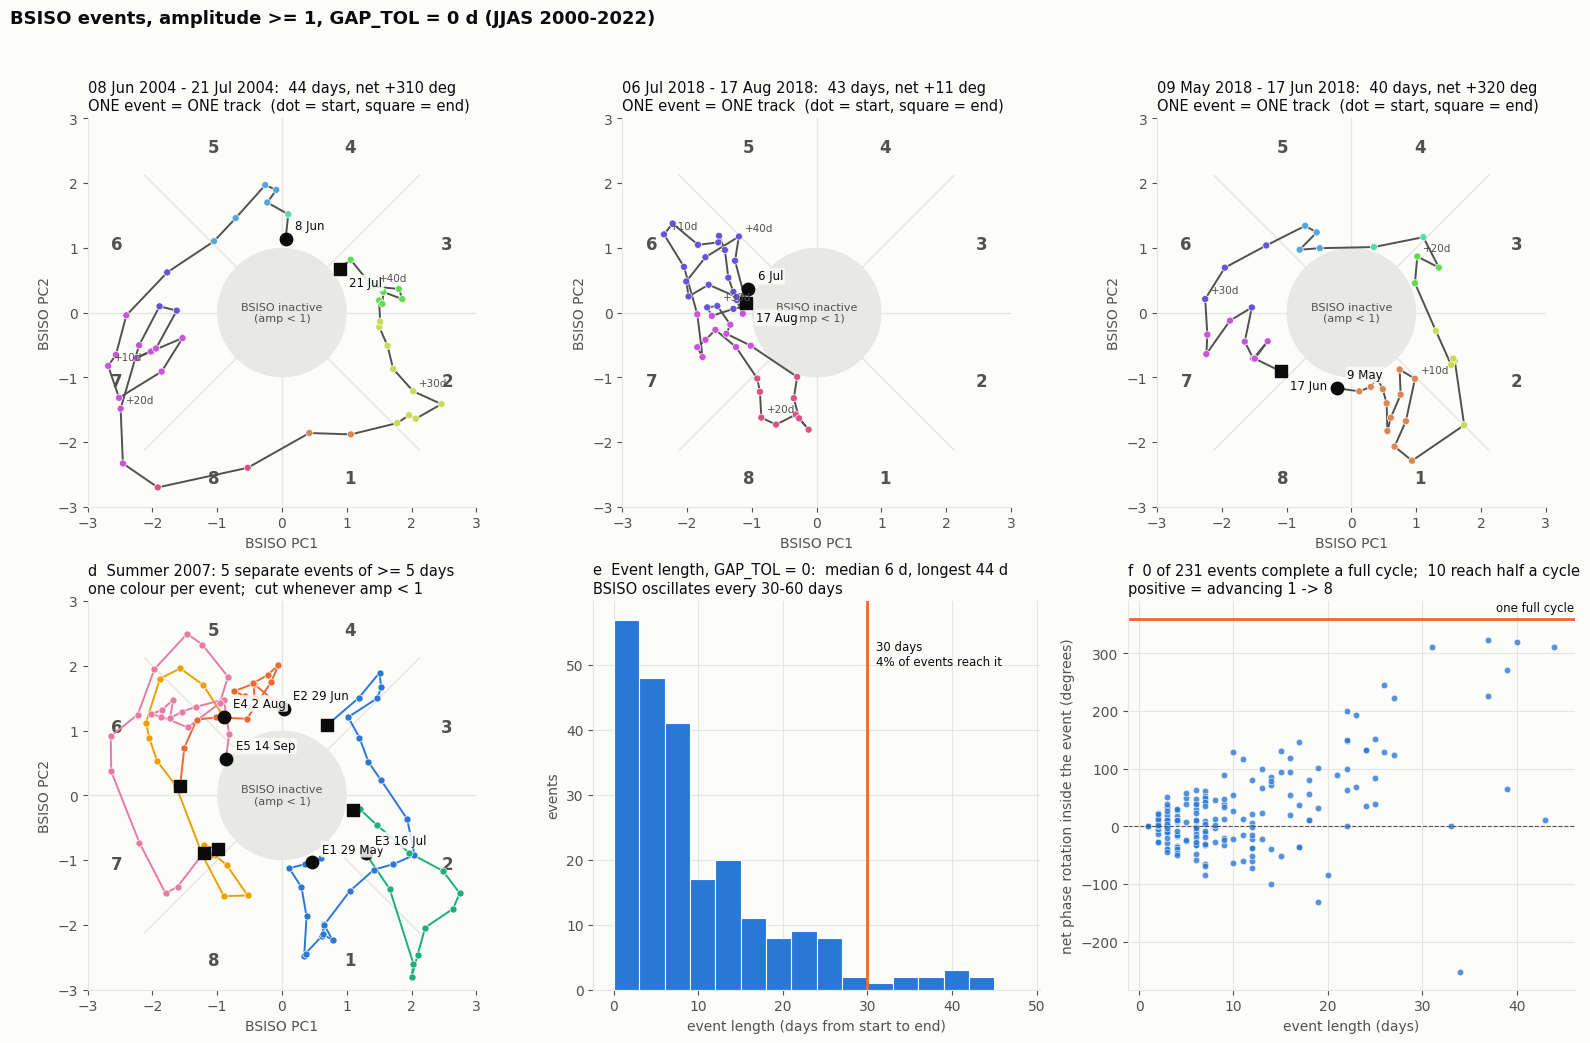

In [24]:
# An EVENT starts the first day amplitude reaches AMP_MIN and ends when it falls below AMP_MIN.
# GAP_TOL = how many consecutive days below AMP_MIN are tolerated INSIDE one event:
#   0 = strict (the event ends the first day amp < 1);  >0 = short dips are bridged.
# This is a DEFINITION CHOICE, not a fact about the index: the table printed below shows how much it matters.
GAP_TOL = 0
MIN_DAYS = 5                                       # events shorter than this are counted but not drawn

bs = bsiso.sort_values("date").reset_index(drop=True)
amp_all, th_all, ph_all = bs["amp"].values, bs["theta"].values, bs["phase"].values
dates_all = pd.DatetimeIndex(bs["date"])


def find_events(gap_tol):
    act = np.where(amp_all >= AMP_MIN)[0]
    runs, s, p = [], act[0], act[0]
    for i in act[1:]:
        if i - p - 1 <= gap_tol:
            p = i
        else:
            runs.append((s, p))
            s = p = i
    runs.append((s, p))
    return runs


def event_table(gap_tol):
    rows = []
    for s, e in find_events(gap_tol):
        seg = np.arange(s, e + 1)
        d = dates_all[seg]
        if not (d.month.isin([6, 7, 8, 9]) & (d.year >= Y0) & (d.year <= Y1)).any():
            continue                                       # keep events that touch a JJAS of the catalogue years
        ia = seg[amp_all[seg] >= AMP_MIN]                  # rotation = steps between consecutive ACTIVE days
        rot = np.degrees(np.angle(np.exp(1j * np.diff(th_all[ia])))).sum()
        rows.append(dict(s=s, e=e, start=d[0], end=d[-1], span=e - s + 1, active=len(ia), rot=rot))
    return pd.DataFrame(rows)


print("HOW MANY EVENTS PER SUMMER, vs how long a dip below 1 is tolerated inside one event")
print(f"{'gap tolerance':>14}{'events':>8}{'/summer':>9}{'median d':>10}{'>=30 d':>8}{'longest':>9}"
      f"{'rot>=180':>10}{'rot>=360':>10}")
for g_ in (0, 1, 2, 3, 5, 7):
    t_ = event_table(g_)
    nsum = t_["start"].dt.year.nunique()
    print(f"{g_:>10} d{' *' if g_ == GAP_TOL else '  '}{len(t_):>8}{len(t_) / (Y1 - Y0 + 1):>9.1f}{t_['span'].median():>10.0f}"
          f"{100 * (t_['span'] >= 30).mean():>7.0f}%{t_['span'].max():>9}{(t_['rot'] >= 180).sum():>10}{(t_['rot'] >= 360).sum():>10}")
print("(* = the setting used below.  rot = net phase rotation inside the event, degrees)")

ET = event_table(GAP_TOL)
print(f"\nGAP_TOL = {GAP_TOL}: {len(ET)} events touching JJAS {Y0}-{Y1}; "
      f"{int((ET['span'] >= MIN_DAYS).sum())} last >= {MIN_DAYS} days (the ones drawn)")


def draw_event(a, s, e, label_days=True, color_by_phase=True, line_color=INK2, tag=None, label_end=True):
    seg = np.arange(s, e + 1)
    xx, yy = bs["pc1"].values[seg], bs["pc2"].values[seg]
    am, ph = amp_all[seg], ph_all[seg].astype(int)
    for i in range(1, len(seg)):
        if am[i - 1] >= AMP_MIN and am[i] >= AMP_MIN:
            a.plot(xx[i - 1:i + 1], yy[i - 1:i + 1], color=line_color, lw=1.4, zorder=3)
        else:                                                # a bridged dip (only when GAP_TOL > 0)
            a.plot(xx[i - 1:i + 1], yy[i - 1:i + 1], color=line_color, lw=0.9, ls=(0, (2, 2)), alpha=0.7, zorder=2)
    act = am >= AMP_MIN
    cols = [PH_COL[p - 1] for p in ph[act]] if color_by_phase else line_color
    a.scatter(xx[act], yy[act], s=26, c=cols, edgecolor=SURF, linewidth=0.5, zorder=4)
    a.scatter(xx[0], yy[0], s=80, color=INK, zorder=6)                                  # start
    a.scatter(xx[-1], yy[-1], s=80, marker="s", color=INK, zorder=6)                    # end
    d0, d1 = dates_all[s], dates_all[e]
    lab0 = (tag + " " if tag else "") + f"{d0.day} {d0.strftime('%b')}"
    a.annotate(lab0, (xx[0], yy[0]), xytext=(7, 7), textcoords="offset points", fontsize=8.5, color=INK, zorder=7,
               bbox=dict(boxstyle="round,pad=0.15", fc=SURF, ec="none", alpha=0.85))
    if label_end:
        a.annotate(f"{d1.day} {d1.strftime('%b')}", (xx[-1], yy[-1]), xytext=(7, -13), textcoords="offset points",
                   fontsize=8.5, color=INK, zorder=7, bbox=dict(boxstyle="round,pad=0.15", fc=SURF, ec="none", alpha=0.85))
    if label_days:
        for k in range(10, len(seg), 10):                    # day counter along the track
            a.annotate(f"+{k}d", (xx[k], yy[k]), xytext=(4, 4), textcoords="offset points", fontsize=7.5,
                       color=INK2, zorder=7)


fig, ax = plt.subplots(2, 3, figsize=(16, 10.6))
longest = ET.sort_values("span", ascending=False).head(3)
for a, (_, r_) in zip(ax[0], longest.iterrows()):
    frame(a, f"{r_['start']:%d %b %Y} - {r_['end']:%d %b %Y}:  {r_['span']} days, net {r_['rot']:+.0f} deg\n"
             "ONE event = ONE track  (dot = start, square = end)")
    draw_event(a, int(r_["s"]), int(r_["e"]))

# (d) every event of one summer, one line colour per event
yr_amp = int(bb.groupby(bb["date"].dt.year)["amp"].mean().idxmax())            # same summer as Step 10
sub = ET[(ET["start"].dt.year == yr_amp) | (ET["end"].dt.year == yr_amp)]
sub = sub[sub["span"] >= MIN_DAYS].reset_index(drop=True)
EVC = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
a = ax[1, 0]
frame(a, f"d  Summer {yr_amp}: {len(sub)} separate events of >= {MIN_DAYS} days\n"
         "one colour per event;  cut whenever amp < 1")
for i, r_ in sub.iterrows():
    draw_event(a, int(r_["s"]), int(r_["e"]), label_days=False, color_by_phase=False,
               line_color=EVC[i % len(EVC)], tag=f"E{i + 1}", label_end=False)
print(f"\nsummer {yr_amp} events drawn:")
print(sub[["start", "end", "span", "rot"]].assign(rot=lambda d_: d_["rot"].round(0)).rename(
    index=lambda i_: f"E{i_ + 1}").to_string())

# (e) how long do events last?
a = ax[1, 1]
a.hist(ET["span"], bins=np.arange(0, ET["span"].max() + 5, 3), color=BLUE, edgecolor=SURF, linewidth=0.8)
a.axvline(30, color=ORANGE, lw=2)
a.text(31, a.get_ylim()[1] * 0.9, f"30 days\n{100 * (ET['span'] >= 30).mean():.0f}% of events reach it",
       color=INK, fontsize=8.5, va="top")
a.set(xlabel="event length (days from start to end)", ylabel="events")
a.set_title(f"e  Event length, GAP_TOL = {GAP_TOL}:  median {ET['span'].median():.0f} d, "
            f"longest {ET['span'].max()} d\nBSISO oscillates every 30-60 days", loc="left", fontsize=10.5)

# (f) does an event ever go round once?
a = ax[1, 2]
a.scatter(ET["span"], ET["rot"], s=22, color=BLUE, edgecolor=SURF, linewidth=0.5, alpha=0.8)
a.axhline(0, color=INK2, lw=0.8, ls="--")
a.axhline(360, color=ORANGE, lw=2)
a.text(a.get_xlim()[1], 368, "one full cycle", color=INK, fontsize=8.5, ha="right", va="bottom")
a.set(xlabel="event length (days)", ylabel="net phase rotation inside the event (degrees)")
a.set_title(f"f  {int((ET['rot'] >= 360).sum())} of {len(ET)} events complete a full cycle;  "
            f"{int((ET['rot'] >= 180).sum())} reach half a cycle\npositive = advancing 1 -> 8", loc="left", fontsize=10.5)

fig.suptitle(f"BSISO events, amplitude >= {AMP_MIN:g}, GAP_TOL = {GAP_TOL} d (JJAS {Y0}-{Y1})", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.955))
plt.savefig("/kaggle/working/K_F11_bsiso_events.png", dpi=150)
plt.show()
ET.assign(start=ET["start"].dt.date, end=ET["end"].dt.date).drop(columns=["s", "e"]).to_csv(
    "/kaggle/working/K11_bsiso_events.csv", index=False)

The TRAJECTORY OF BSISO ( AMPLITUDE GATED- TO SEE IF THEY FOLLOW PHASE ORDERING)

background: IMERG JJAS-mean rainfall (from step 11A)


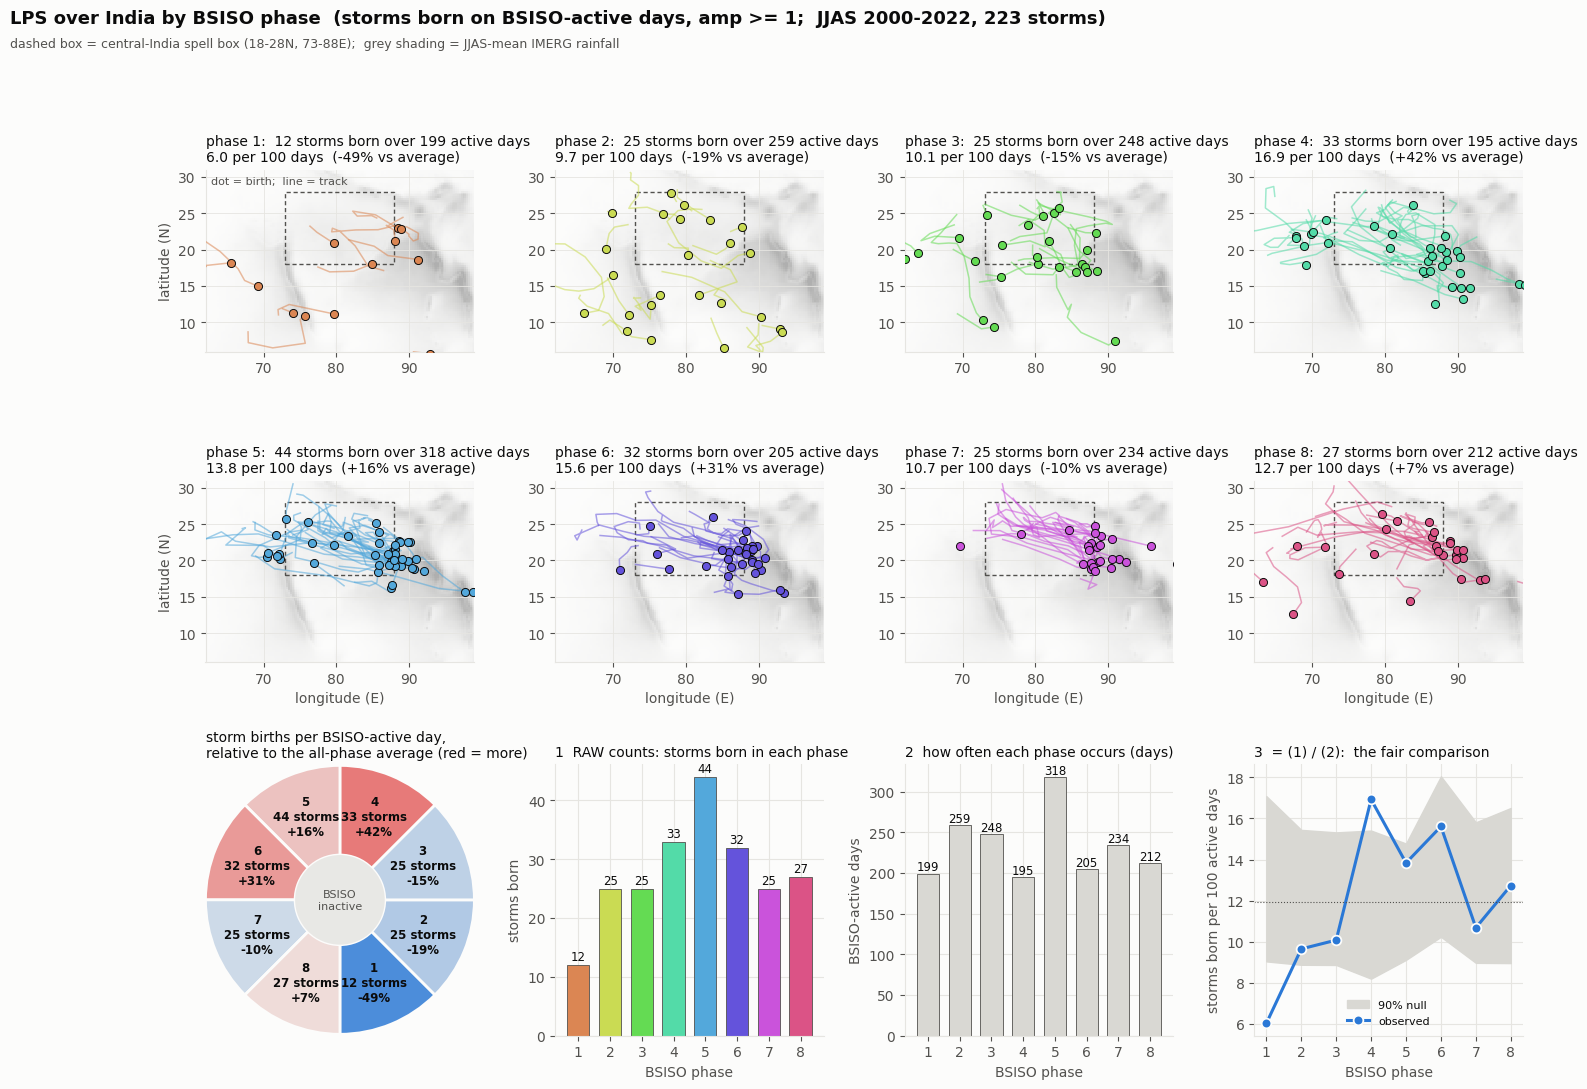

storms born / active days / per 100 days / vs average
  phase 1:  12 / 199 /   6.0 /   -49%
  phase 2:  25 / 259 /   9.7 /   -19%
  phase 3:  25 / 248 /  10.1 /   -15%
  phase 4:  33 / 195 /  16.9 /   +42%
  phase 5:  44 / 318 /  13.8 /   +16%
  phase 6:  32 / 205 /  15.6 /   +31%
  phase 7:  25 / 234 /  10.7 /   -10%
  phase 8:  27 / 212 /  12.7 /    +7%
  all    : 223 / 1870 /  11.9


In [25]:
from matplotlib.patches import Wedge, Rectangle

LON0, LON1, LAT0, LAT1 = 62, 99, 6, 31
trk = lps.sort_values(["track", "date"])
tracks = {t: g_[["lon", "lat"]].values for t, g_ in trk.groupby("track")}
births = fg.copy()
births["ph"] = births["phase"].astype(int)
have_bg = all(v in globals() for v in ("rain", "lat", "lon"))
if have_bg:
    mean_rain = rain.mean(axis=0)                                   # (lat ascending, lon)
    print("background: IMERG JJAS-mean rainfall (from step 11A)")
else:
    print("background: none (run step 11A first if you want the rainfall background)")

fig = plt.figure(figsize=(17, 11.6))
gs_ = fig.add_gridspec(3, 4, height_ratios=[1, 1, 1.15], hspace=0.30, wspace=0.30)
ov_pct = lambda r_: 100 * (r_ / ov_g - 1)

for k in range(1, 9):
    a = fig.add_subplot(gs_[(k - 1) // 4, (k - 1) % 4])
    if have_bg:
        a.pcolormesh(lon, lat, mean_rain, cmap="Greys", vmin=0, vmax=30, alpha=0.30, shading="auto", zorder=0)
    a.add_patch(Rectangle((73, 18), 15, 10, fill=False, ec=INK2, lw=1.0, ls=(0, (3, 2)), zorder=2))   # CMZ box
    bk = births[births["ph"] == k]
    for t in bk["track"]:
        xy = tracks[t]
        a.plot(xy[:, 0], xy[:, 1], color=PH_COL[k - 1], lw=1.1, alpha=0.55, zorder=3)
    a.scatter(bk["lon"], bk["lat"], s=34, color=PH_COL[k - 1], edgecolor=INK, linewidth=0.7, zorder=5)
    a.set(xlim=(LON0, LON1), ylim=(LAT0, LAT1), aspect="equal")
    a.grid(True, color=GRID, lw=0.6)
    a.set_title(f"phase {k}:  {int(cnt_g[k - 1])} storms born over {int(pdays_g[k])} active days\n"
                f"{100 * rate_g[k - 1]:.1f} per 100 days  ({ov_pct(rate_g[k - 1]):+.0f}% vs average)",
                loc="left", fontsize=10)
    if k in (1, 5):
        a.set_ylabel("latitude (N)")
    if k > 4:
        a.set_xlabel("longitude (E)")
    if k == 1:
        a.text(LON0 + 0.8, LAT1 - 0.8, "dot = birth;  line = track", fontsize=8, color=INK2, va="top")

# --- bottom row: the rose (phase space, normalised) and the three bar charts that build the rate ---
a = fig.add_subplot(gs_[2, 0])
norm_lim = 60.0
for k in range(1, 9):
    r_pct = ov_pct(rate_g[k - 1])
    col = dv(0.5 + 0.5 * np.clip(r_pct, -norm_lim, norm_lim) / norm_lim)
    a.add_patch(Wedge((0, 0), R, (k - 1) * 45 - 90, k * 45 - 90, width=R - AMP_MIN, fc=col, ec=SURF, lw=2))
    tx, ty = to_xy((k - 0.5) * 45, (R + AMP_MIN) / 2)
    a.text(tx, ty, f"{k}\n{int(cnt_g[k - 1])} storms\n{r_pct:+.0f}%", ha="center", va="center", fontsize=8.5, color=INK,
           fontweight="bold")
a.add_patch(plt.Circle((0, 0), AMP_MIN, color=NULLC, alpha=0.55, lw=0))
a.text(0, 0, f"BSISO\ninactive", ha="center", va="center", fontsize=8, color=INK2)
a.set(xlim=(-R, R), ylim=(-R, R), aspect="equal", xticks=[], yticks=[])
a.grid(False)
for s_ in a.spines.values():
    s_.set_visible(False)
a.set_title("storm births per BSISO-active day,\nrelative to the all-phase average (red = more)", loc="left", fontsize=10)

xs = np.arange(1, 9)
a = fig.add_subplot(gs_[2, 1])
a.bar(xs, cnt_g, color=[PH_COL[k - 1] for k in xs], edgecolor=INK2, linewidth=0.6, width=0.7)
for k in xs:
    a.text(k, cnt_g[k - 1] + 0.8, str(int(cnt_g[k - 1])), ha="center", fontsize=8.5)
a.set(xlabel="BSISO phase", ylabel="storms born", xticks=xs)
a.set_title("1  RAW counts: storms born in each phase", loc="left", fontsize=10)

a = fig.add_subplot(gs_[2, 2])
a.bar(xs, pdays_g.values, color=NULLC, edgecolor=INK2, linewidth=0.6, width=0.7)
for k in xs:
    a.text(k, pdays_g.values[k - 1] + 4, str(int(pdays_g.values[k - 1])), ha="center", fontsize=8.5)
a.set(xlabel="BSISO phase", ylabel="BSISO-active days", xticks=xs)
a.set_title("2  how often each phase occurs (days)", loc="left", fontsize=10)

a = fig.add_subplot(gs_[2, 3])
a.fill_between(xs, 100 * tG["null_p05"].values, 100 * tG["null_p95"].values, color=NULLC, label="90% null")
a.plot(xs, 100 * rate_g, "o-", color=BLUE, lw=2.2, ms=7, mec=SURF, mew=1.3, label="observed")
a.axhline(100 * ov_g, color=INK2, lw=0.8, ls=":")
a.set(xlabel="BSISO phase", ylabel="storms born per 100 active days", xticks=xs)
a.set_title("3  = (1) / (2):  the fair comparison", loc="left", fontsize=10)
a.legend(frameon=False, fontsize=8, loc="lower center")

fig.suptitle(f"LPS over India by BSISO phase  (storms born on BSISO-active days, amp >= {AMP_MIN:g};  "
             f"JJAS {Y0}-{Y1}, {len(births)} storms)", x=0.01, y=0.995, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.962, "dashed box = central-India spell box (18-28N, 73-88E);  grey shading = JJAS-mean IMERG rainfall"
         if have_bg else "dashed box = central-India spell box (18-28N, 73-88E)", fontsize=9, color=INK2)
plt.savefig("/kaggle/working/K_F12_lps_map_by_phase.png", dpi=150, bbox_inches="tight")
plt.show()

print("storms born / active days / per 100 days / vs average")
for k in range(1, 9):
    print(f"  phase {k}: {int(cnt_g[k - 1]):>3} / {int(pdays_g[k]):>3} / {100 * rate_g[k - 1]:>5.1f} / {ov_pct(rate_g[k - 1]):>+5.0f}%")
print(f"  all    : {int(cnt_g.sum()):>3} / {int(pdays_g.sum()):>3} / {100 * ov_g:>5.1f}")

In [26]:
import numpy as np
import pandas as pd

N_PERM = 1000                                    # use 300 while debugging
PHI = np.deg2rad((np.arange(1, 9) - 0.5) * 45)   # centre angle of each phase wedge


def first_rows(df):
    return df.sort_values("date").drop_duplicates("track").dropna(subset=["phase", "amp"])


def curve(first, pdays):
    cnt = first["phase"].astype(int).value_counts().reindex(range(1, 9), fill_value=0)
    return cnt.values, (cnt / pdays).values, cnt.sum() / pdays.sum()


def spread(rate, ov):
    """OMNIBUS statistic: how far the 8 phase rates sit from a flat line."""
    return float((((rate - ov) ** 2) / ov).sum())


def harmonic(rate):
    """SINGLE-BUMP statistic: size of the best smooth hump around the phase circle (relative to the mean)."""
    w = rate / rate.mean() - 1
    z = (2 / 8) * np.sum(w * np.exp(1j * PHI))
    return abs(z), (np.degrees(np.angle(z)) % 360) / 45 + 0.5          # amplitude, phase at the peak (1..8)


def genesis_pattern(df, yrs, amp_min, label, rng, n=N_PERM):
    """df needs columns track, date.  Storms are moved rigidly to another year; the gate is re-applied each time."""
    sd = bsiso[bsiso["date"].dt.month.between(6, 9) & bsiso["date"].dt.year.isin(yrs) & (bsiso["amp"] >= amp_min)]
    pdays = sd["phase"].astype(int).value_counts().reindex(range(1, 9), fill_value=0)
    f = first_rows(df.merge(bsiso, on="date", how="left"))
    f = f[f["amp"] >= amp_min]
    cnt, rate, ov = curve(f, pdays)
    base = df[["track", "date"]].copy()
    base["strength"] = 0.0
    R_, S_, H_ = [], [], []
    for _ in range(n):
        sh = attach_phase(redate_tracks(base, rng, yrs), bsiso)
        ff = first_rows(sh)
        ff = ff[ff["amp"] >= amp_min]
        _, r2, o2 = curve(ff, pdays)
        R_.append(r2)
        S_.append(spread(r2, o2))
        H_.append(harmonic(r2)[0])
    R_, S_, H_ = np.array(R_), np.array(S_), np.array(H_)
    lo, hi = np.percentile(R_, [5, 95], axis=0)
    outside = (rate < lo) | (rate > hi)
    n_out_null = ((R_ < lo) | (R_ > hi)).sum(axis=1)
    h_obs, pk = harmonic(rate)
    out = dict(label=label, storms=int(cnt.sum()), days=int(pdays.sum()), ratio=rate.max() / rate.min(),
               n_out=int(outside.sum()), p_nout=(1 + np.sum(n_out_null >= outside.sum())) / (n + 1),
               p_omni=(1 + np.sum(S_ >= spread(rate, ov))) / (n + 1), amp=h_obs, peak=pk,
               p_bump=(1 + np.sum(H_ >= h_obs)) / (n + 1))
    mu, sdv = R_.mean(axis=0), R_.std(axis=0)
    t = pd.DataFrame({"storms": cnt, "days": pdays.values, "per_100d": 100 * rate, "null_p05": 100 * lo,
                      "null_p95": 100 * hi, "outside": np.where(outside, "YES", "no"),
                      "z": (rate - mu) / sdv}, index=pd.Index(range(1, 9), name="phase"))
    print(f"\n=== {label}  | {out['storms']} storms | {out['days']} days ===")
    print(t.round(2).to_string())
    return out


rng = np.random.default_rng(11)
results = []
for amp_min, nm in ((0.0, "all days"), (1.0, "gated amp>=1")):
    results.append(genesis_pattern(lps[["track", "date"]].copy(), np.asarray(years), amp_min,
                                   f"this catalogue, {nm}", rng))
# If you upload the ERA5 Zenodo parquet as a dataset, the same call works on it, e.g.:
#   e = pd.read_parquet(".../lps_era5_india_jjas_1979_2019.parquet").rename(columns={"track_id": "track"})
#   e["date"] = pd.to_datetime(e["date"]);  e = e[e["date"].dt.year >= 1981]
#   results.append(genesis_pattern(e[["track", "date"]], np.arange(1981, 2020), 1.0, "ERA5 1981-2019, gated", rng))

print("\n\nSUMMARY")
print(f"{'':<34}{'storms':>7}{'max/min':>9}{'omnibus p':>11}{'single-bump p':>15}{'peak':>6}{'bump size':>11}{'outside band':>14}")
for r in results:
    print(f"{r['label']:<34}{r['storms']:>7}{r['ratio']:>8.2f}x{r['p_omni']:>11.4f}{r['p_bump']:>15.4f}"
          f"{r['peak']:>6.1f}{100 * r['amp']:>10.0f}%{r['n_out']:>8} of 8")
print(f"\np floor = {1 / (N_PERM + 1):.4f}.  'outside band' = phases whose own 90% null band excludes them "
      f"(chance expectation 0.8 of 8).")
pd.DataFrame(results).to_csv("/kaggle/working/K13_genesis_pattern_stats.csv", index=False)


=== this catalogue, all days  | 345 storms | 2806 days ===
       storms  days  per_100d  null_p05  null_p95 outside     z
phase                                                          
1          19   288      6.60      9.38     15.30     YES -3.15
2          39   401      9.73      9.98     15.21     YES -1.80
3          49   388     12.63      9.54     14.69      no  0.33
4          48   322     14.91      9.01     14.60     YES  1.80
5          74   473     15.64      9.73     14.59     YES  2.36
6          43   299     14.38     10.03     16.39      no  0.64
7          36   333     10.81      9.31     15.02      no -0.81
8          37   302     12.25      9.27     15.23      no  0.09

=== this catalogue, gated amp>=1  | 223 storms | 1870 days ===
       storms  days  per_100d  null_p05  null_p95 outside     z
phase                                                          
1          12   199      6.03      9.05     16.58     YES -2.92
2          25   259      9.65      9.27     

In [30]:
import numpy as np
import pandas as pd

N_PERM = 1000                                    # use 300 while debugging
PHI = np.deg2rad((np.arange(1, 9) - 0.5) * 45)   # centre angle of each phase wedge


def first_rows(df):
    return df.sort_values("date").drop_duplicates("track").dropna(subset=["phase", "amp"])


def curve(first, pdays):
    cnt = first["phase"].astype(int).value_counts().reindex(range(1, 9), fill_value=0)
    return cnt.values, (cnt / pdays).values, cnt.sum() / pdays.sum()


def spread(rate, ov):
    """OMNIBUS statistic: how far the 8 phase rates sit from a flat line."""
    return float((((rate - ov) ** 2) / ov).sum())


def harmonic(rate):
    """SINGLE-HUMP statistic: size of the best smooth hump around the phase circle (relative to the mean)."""
    w = rate / rate.mean() - 1
    z = (2 / 8) * np.sum(w * np.exp(1j * PHI))
    return abs(z), (np.degrees(np.angle(z)) % 360) / 45 + 0.5          # size, phase at the peak (1..8)


def genesis_pattern(df, yrs, amp_min, label, rng, n=N_PERM):
    """df needs columns track, date.  Storms are moved rigidly to another year; the gate is re-applied each time."""
    sd = bsiso[bsiso["date"].dt.month.between(6, 9) & bsiso["date"].dt.year.isin(yrs) & (bsiso["amp"] >= amp_min)]
    pdays = sd["phase"].astype(int).value_counts().reindex(range(1, 9), fill_value=0)
    f = first_rows(df.merge(bsiso, on="date", how="left"))
    f = f[f["amp"] >= amp_min]
    cnt, rate, ov = curve(f, pdays)
    base = df[["track", "date"]].copy()
    base["strength"] = 0.0
    R_, S_, H_ = [], [], []
    for _ in range(n):
        sh = attach_phase(redate_tracks(base, rng, yrs), bsiso)
        ff = first_rows(sh)
        ff = ff[ff["amp"] >= amp_min]
        _, r2, o2 = curve(ff, pdays)
        R_.append(r2)
        S_.append(spread(r2, o2))
        H_.append(harmonic(r2)[0])
    R_, S_, H_ = np.array(R_), np.array(S_), np.array(H_)
    lo, hi = np.percentile(R_, [5, 95], axis=0)
    h_obs, pk = harmonic(rate)
    n_out = int(((rate < lo) | (rate > hi)).sum())
    print(f"\n{label}: {int(cnt.sum())} storms, {int(pdays.sum())} days")
    print("phase  storms  per 100 d  chance range  vs chance")
    for k in range(8):
        flag = "BELOW" if rate[k] < lo[k] else ("ABOVE" if rate[k] > hi[k] else "-")
        print(f"  {k + 1}     {cnt[k]:>3}     {100 * rate[k]:>5.1f}    {100 * lo[k]:>4.1f}-{100 * hi[k]:<5.1f}    {flag}")
    return dict(label=label, storms=int(cnt.sum()), p_omni=(1 + np.sum(S_ >= spread(rate, ov))) / (n + 1),
                p_hump=(1 + np.sum(H_ >= h_obs)) / (n + 1), peak=pk, size=h_obs, n_out=n_out,
                ratio=rate.max() / rate.min())


rng = np.random.default_rng(11)
results = []
for amp_min, nm in ((0.0, "ALL DAYS"), (1.0, "GATED (amp >= 1)")):
    results.append(genesis_pattern(lps[["track", "date"]].copy(), np.asarray(years), amp_min, nm, rng))
# If you upload the ERA5 Zenodo parquet as a dataset, the same call works on it, e.g.:
#   e = pd.read_parquet(".../lps_era5_india_jjas_1979_2019.parquet").rename(columns={"track_id": "track"})
#   e["date"] = pd.to_datetime(e["date"]);  e = e[e["date"].dt.year >= 1981]
#   results.append(genesis_pattern(e[["track", "date"]], np.arange(1981, 2020), 1.0, "ERA5 gated", rng))

print("\n" + "=" * 62)
print("SUMMARY            storms  omnibus p  hump p  peak  outside")
for r in results:
    print(f"{r['label']:<18}{r['storms']:>6}{r['p_omni']:>11.3f}{r['p_hump']:>8.3f}{r['peak']:>6.1f}"
          f"{r['n_out']:>6} of 8")
print("=" * 62)
print("omnibus p : do the 8 phases differ from flat? (pre-specified)")
print("hump p    : one smooth hump? (added after looking)")
print("peak      : phase at the top of the hump")
print("outside   : phases beyond own chance range (chance ~0.8)")
print(f"smallest possible p = {1 / (N_PERM + 1):.3f}")
pd.DataFrame(results).to_csv("/kaggle/working/K13_genesis_pattern_stats.csv", index=False)


ALL DAYS: 345 storms, 2806 days
phase  storms  per 100 d  chance range  vs chance
  1      19       6.6     9.4-15.3     BELOW
  2      39       9.7    10.0-15.2     BELOW
  3      49      12.6     9.5-14.7     -
  4      48      14.9     9.0-14.6     ABOVE
  5      74      15.6     9.7-14.6     ABOVE
  6      43      14.4    10.0-16.4     -
  7      36      10.8     9.3-15.0     -
  8      37      12.3     9.3-15.2     -

GATED (amp >= 1): 223 storms, 1870 days
phase  storms  per 100 d  chance range  vs chance
  1      12       6.0     9.0-16.6     BELOW
  2      25       9.7     9.3-15.8     -
  3      25      10.1     8.9-15.7     -
  4      33      16.9     8.2-15.9     ABOVE
  5      44      13.8     9.1-14.8     -
  6      32      15.6    10.2-17.6     -
  7      25      10.7     9.0-16.2     -
  8      27      12.7     9.0-16.5     -

SUMMARY            storms  omnibus p  hump p  peak  outside
ALL DAYS             345      0.019   0.001   5.0     4 of 8
GATED (amp >= 1)     223

In [33]:
yrs_ = np.asarray(years)
b = bsiso[bsiso["date"].dt.month.between(6, 9) & bsiso["date"].dt.year.isin(yrs_)].copy()
b["ph"] = b["phase"].astype(int)
b["yr"] = b["date"].dt.year
rng = np.random.default_rng(3)

bb = b[b["amp"] >= 1]                                       # BSISO-active days only
cnt = pd.crosstab(bb["yr"], bb["ph"]).reindex(index=yrs_, columns=range(1, 9), fill_value=0)
share = cnt.sum().values / cnt.values.sum()
boot = []
for _ in range(5000):                                       # resample whole SUMMERS, not days
    pick = rng.choice(len(yrs_), len(yrs_))
    c = cnt.values[pick].sum(axis=0)
    boot.append(c / c.sum())
lo, hi = np.percentile(np.array(boot), [5, 95], axis=0)
per_year = cnt.values / cnt.values.sum(axis=1, keepdims=True)

# dwell time: consecutive days the BSISO stays in one phase while active
rows = []
for yr, g in b.groupby("yr"):
    g = g.sort_values("date")
    act = g["amp"] >= 1
    new = (g["ph"] != g["ph"].shift()) | (~act) | (g["date"].diff().dt.days != 1)
    gid = new.cumsum()
    for _, s in g[act].groupby(gid[act]):
        rows.append((int(s["ph"].iloc[0]), len(s)))
dwell = pd.DataFrame(rows, columns=["ph", "days"]).groupby("ph")["days"].mean()

print(f"BSISO-active days (amp >= 1), JJAS {yrs_.min()}-{yrs_.max()}")
print("phase  share of days   range (90%)  summers>12.5%  stays (days)")
for k in range(8):
    print(f"  {k + 1}      {100 * share[k]:>4.1f}%       {100 * lo[k]:>4.1f}-{100 * hi[k]:<5.1f}"
          f"     {(per_year[:, k] > 0.125).sum():>2} of {len(yrs_)}       {dwell[k + 1]:>3.1f}")
print("\nflat = 12.5% per phase;  range = 90% interval (resampled summers)")
print("stays = average consecutive days in that phase")

BSISO-active days (amp >= 1), JJAS 2000-2022
phase  share of days   range (90%)  summers>12.5%  stays (days)
  1      10.6%        8.3-13.2       6 of 23       3.1
  2      13.9%       11.2-16.7      13 of 23       3.3
  3      13.3%       10.6-16.4       9 of 23       3.1
  4      10.4%        8.1-12.8      10 of 23       2.9
  5      17.0%       14.4-19.6      16 of 23       3.8
  6      11.0%        8.7-13.4       7 of 23       2.8
  7      12.5%       10.2-14.8      12 of 23       3.4
  8      11.3%        8.8-14.3       9 of 23       3.3

flat = 12.5% per phase;  range = 90% interval (resampled summers)
stays = average consecutive days in that phase
